# DS 5007: Natural Language Processing — Assignment 2
## Neural NLP Pipeline — a continuation of the BBC Urdu NLP pipeline

**Muhammad Usama** · **i25-8007** · Section **DS-A**

GitHub repository: https://github.com/<github-username>/i25-8007-NLP-Assignment2

Everything is implemented from scratch in PyTorch / NumPy: no pretrained models, no Gensim, no
HuggingFace, and none of `nn.Transformer`, `nn.MultiheadAttention`, `nn.TransformerEncoder`.
scikit-learn is used only for the t-SNE projection. All logic lives in `src/` (unit-tested in
`tests/`); this notebook runs the complete pipeline end to end and shows every result.

**Inputs** — the unmodified Assignment 1 deliverables in `data/`: `cleaned.txt` (primary corpus),
`raw.txt` (ablation baseline) and `Metadata.json` (topic information); `src/a1_preprocess.py` is the
unmodified Assignment 1 normaliser / tokenizer / lemmatizer / stemmer.

In [1]:
%matplotlib inline
import os, sys, json, time, platform, copy
from pathlib import Path
from collections import Counter
sys.path.insert(0, str(Path.cwd() / "src"))

import numpy as np, pandas as pd, torch, matplotlib, sklearn
import config as C
from plotting import plt, savefig, PALETTE
from glosses import gloss, with_gloss

torch.set_num_threads(4)
pd.set_option("display.max_colwidth", 220); pd.set_option("display.width", 250)
RUN = {'seeds': [42, 7, 123], 'w2v_epochs': 15, 'seq_max_epochs': 60, 'tf_epochs': 20, 'w2v_limit': None}            # seeds and epoch budgets used in this run
RESULTS = {}                      # collected numbers -> outputs/results.json
print("Python", platform.python_version(), "| torch", torch.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__, "| scikit-learn", sklearn.__version__)
print("CPU threads:", torch.get_num_threads(), "| run settings:", RUN)
print("Student:", C.STUDENT_NAME, "|", C.STUDENT_ID, "|", C.SECTION, "| repository:", C.REPO_URL)

Python 3.13.18 | torch 2.15.0+cpu | numpy 2.5.3 | pandas 3.0.5 | matplotlib 3.11.2 | scikit-learn 1.9.1
CPU threads: 4 | run settings: {'seeds': [42, 7, 123], 'w2v_epochs': 15, 'seq_max_epochs': 60, 'tf_epochs': 20, 'w2v_limit': None}
Student: Muhammad Usama | i25-8007 | DS-A | repository: https://github.com/<github-username>/i25-8007-NLP-Assignment2


## 0. Data and the Assignment 1 pipeline

`cleaned.txt` is the output of the A1 pipeline (normalise → segment → tokenize → lemmatize →
stem), one sentence per line, articles separated by `### ARTICLE n ###`. Re-running the A1 module on
`raw.txt` reproduces `cleaned.txt` **exactly**, so every cleaned token can be traced back to its
surface form — Part 2 builds the POS tagger on this alignment.

In [2]:
from corpus import (load_cleaned_articles, load_metadata, flatten, build_vocab, token_counts,
                    save_word2idx, load_raw_sentences_unprocessed, is_symbol)
from a1_bridge import aligned_corpus, a1_normalize

arts = load_cleaned_articles(); meta = load_metadata(); sents = flatten(arts)
counts = token_counts(sents)
print(f"articles: {len(arts)} | sentences: {len(sents):,} | tokens: {sum(map(len, sents)):,} | "
      f"types: {len(counts):,}")
t0 = time.time(); aligned = aligned_corpus()
print(f"A1 pipeline re-run on raw.txt == cleaned.txt for all {len(aligned)} articles "
      f"({sum(len(a) for a in aligned):,} sentences, {time.time()-t0:.1f}s)")
r = aligned[0][0]
pd.DataFrame([{"cleaned token": x["clean"], "surface token": x["surface"], "source word": x["word"]}
              for x in r[:12]])

articles: 250 | sentences: 15,018 | tokens: 434,404 | types: 10,943


A1 pipeline re-run on raw.txt == cleaned.txt for all 250 articles (15,018 sentences, 1.5s)


,cleaned token,surface token,source word
0,پانچ,پانچ,پانچ
1,سالہ,سالہ,سالہ
2,سہیل,سہیل,سہیل
3,احمد,احمد,احمد
4,دیکھ,دیکھ,دیکھ
5,سکت,سکتے,سکتے
6,تھے,تھے,تھے
7,کہ,کہ,کہ
8,ان,ان,ان
9,کے,کے,کے


### 0.1 Topic categories (used in Parts 1–3)

Each article is assigned to one of the 5 categories of the brief (Section 6.1). The English
indicative keywords were translated and expanded into Urdu keyword lists, every keyword was passed
through the A1 pipeline so it matches the stemmed text, and each article is scored with

$S_c = \text{(keyword hits per 100 body tokens)} + \text{(keyword hits in the headline)} + 0.5\,\times\text{(BBC topic tags of } c)$

and assigned to $\arg\max_c S_c$. After reading all 250 headlines, 9 keyword collisions were
corrected by hand (listed below with the reason, e.g. *جنگ* = the newspaper *Jang*, not "war").

In [3]:
from topics import assign_categories, KEYWORDS, OVERRIDES, normalized_keywords
recs = assign_categories()
labels_all = np.array([r["label_id"] for r in recs])
dist = pd.Series([r["label"] for r in recs]).value_counts().reindex(C.CATEGORIES)
brief_kw = {"Politics": "election, government, minister, parliament",
            "Sports": "cricket, match, team, player, score",
            "Economy": "inflation, trade, bank, GDP, budget",
            "International": "UN, treaty, foreign, bilateral, conflict",
            "Health & Society": "hospital, disease, vaccine, flood, education"}
display(pd.DataFrame({"category": C.CATEGORIES, "brief keywords": [brief_kw[c] for c in C.CATEGORIES],
                      "Urdu keywords": [len(normalized_keywords()[c]) for c in C.CATEGORIES],
                      "first Urdu keywords": ["، ".join(KEYWORDS[c][:6]) for c in C.CATEGORIES],
                      "articles": dist.values}))
pd.DataFrame([{"article": n, "automatic": recs[n-1]["auto_label"], "final": lab, "reason": why}
              for n, (lab, why) in OVERRIDES.items()])

,category,brief keywords,Urdu keywords,first Urdu keywords,articles
0,Politics,"election, government, minister, parliament",45,انتخابات، الیکشن، حکومت، حکومتی، وزیر، وزیراعظم,25
1,Sports,"cricket, match, team, player, score",39,کرکٹ، میچ، ٹیم، کھلاڑی، سکور، کھلاڑیوں,20
2,Economy,"inflation, trade, bank, GDP, budget",44,مہنگائی، افراط زر، تجارت، تجارتی، بینک، جی ڈی پی,22
3,International,"UN, treaty, foreign, bilateral, conflict",39,اقوام متحدہ، معاہدہ، معاہدے، خارجہ، غیر ملکی، دو طرفہ,66
4,Health & Society,"hospital, disease, vaccine, flood, education",52,ہسپتال، بیماری، ویکسین، سیلاب، تعلیم، تعلیمی,117


,article,automatic,final,reason
0,30,Politics,Health & Society,"royal-family human-interest story, not politics"
1,107,Economy,International,"Xi Jinping - Pezeshkian meeting: diplomacy, not oil trade"
2,135,International,Health & Society,'negotiations' are ransom talks with kidnappers (crime)
3,172,International,Politics,"'جنگ' is the newspaper Jang, not 'war'; press-freedom story"
4,199,Economy,International,US visa-bond policy for foreign nationals; 'dollar' is the bond
5,203,Politics,International,Ahmadinejad accused of links with Israel (Iran-Israel war)
6,207,Politics,Economy,Google opens its first office in Karachi: investment/business
7,211,Politics,Economy,launch of Pakistan's largest data centre: investment/business
8,231,Health & Society,International,9/11 accused Ramzi al-Shibh before a US military court


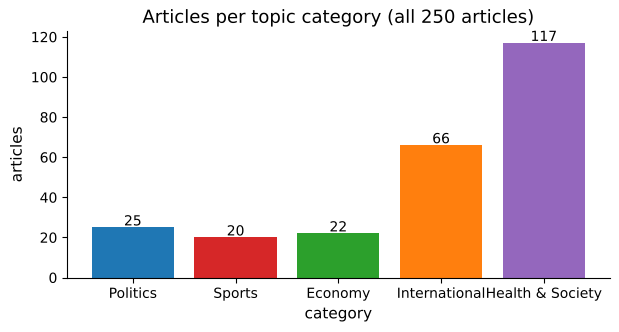

{'Politics': 25, 'Sports': 20, 'Economy': 22, 'International': 66, 'Health & Society': 117}


In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(dist.index, dist.values, color=PALETTE[:5])
for i, v in enumerate(dist.values): ax.text(i, v + 1, str(v), ha="center")
ax.set_title("Articles per topic category (all 250 articles)"); ax.set_xlabel("category"); ax.set_ylabel("articles")
savefig(fig, "topic_distribution.png"); plt.show()
RESULTS["topic_distribution"] = dist.to_dict()
print(dist.to_dict())

# Part 1 — Word Embeddings

## 1.1 TF-IDF weighting

**Vocabulary (shared by all parts):** the 10,000 most frequent tokens of `cleaned.txt` get ids
0–9,999 (ties broken alphabetically), every other token maps to `<UNK>` (id 10,000). `<PAD>` (id
10,001) exists only for the neural models. The term–document matrix therefore has |V| = 10,001 rows
(10,000 words + `<UNK>`) and N = 250 columns (articles); entry = raw count TF(w, d).

$\text{TF-IDF}(w,d) = \text{TF}(w,d)\times \log\big[N / (1+\text{df}(w))\big]$ (natural log).

In [5]:
from part1_counts import term_document_counts, tfidf, top_words_per_category
w2i = build_vocab(sents); save_word2idx(w2i)
i2w = [None] * len(w2i)
for w, i in w2i.items(): i2w[i] = w
cov = sum(counts[w] for w in w2i if w in counts) / sum(counts.values())
print(f"word2idx.json: {len(w2i):,} entries = 10,000 words + <UNK> ({w2i[C.UNK]}) + <PAD> ({w2i[C.PAD]})")
print(f"the 10,000 words cover {100*cov:.2f}% of all tokens; {len(counts) - C.VOCAB_SIZE:,} rare types -> <UNK>")

td = term_document_counts(arts, w2i)
X_tfidf, idf, df = tfidf(td)
np.save(C.TFIDF_NPY, X_tfidf.astype(np.float32))
print(f"term-document matrix: {td.shape} (terms x documents), {int(td.sum()):,} tokens, "
      f"<UNK> occurrences: {int(td[w2i[C.UNK]].sum())}")
print(f"saved {C.TFIDF_NPY.relative_to(Path.cwd())}: shape {X_tfidf.shape}, float32")
print("note: a word present in all 250 articles (df = 250) gets idf = log(250/251) < 0 under this formula")
pd.DataFrame([{"token": w, "gloss": gloss(w), "TF in article 1": int(td[w2i[w], 0]),
               "df": int(df[w2i[w]]), "idf": round(float(idf[w2i[w]]), 4),
               "TF-IDF in article 1": round(float(X_tfidf[w2i[w], 0]), 3)}
              for w in ["کے", "پاکستان", "صحت", "ڈاکٹر", "سہیل"]])

word2idx.json: 10,002 entries = 10,000 words + <UNK> (10000) + <PAD> (10001)
the 10,000 words cover 99.78% of all tokens; 943 rare types -> <UNK>
term-document matrix: (10001, 250) (terms x documents), 434,404 tokens, <UNK> occurrences: 943
saved embeddings/tfidf_matrix.npy: shape (10001, 250), float32
note: a word present in all 250 articles (df = 250) gets idf = log(250/251) < 0 under this formula


,token,gloss,TF in article 1,df,idf,TF-IDF in article 1
0,کے,of (genitive),63,250,-0.0040,-0.251
1,پاکستان,Pakistan,0,110,0.8119,0.000
2,صحت,health,0,41,1.7838,0.000
3,ڈاکٹر,doctor,0,61,1.3943,0.000
4,سہیل,Sohail (name),19,10,3.1236,59.348


**Top-10 most discriminative words per topic category.** Each document column is L2-normalised (so
long articles do not dominate) and words are ranked by
mean TF-IDF inside the category − mean TF-IDF in the other categories; a word must occur in at
least 2 articles of the category, and punctuation / placeholders are skipped.

In [6]:
tops = top_words_per_category(X_tfidf, labels_all.tolist(), i2w, k=10)
top_df = pd.DataFrame({C.CATEGORIES[c]: [with_gloss(w) for w, _ in lst] for c, lst in tops.items()},
                      index=range(1, 11))
RESULTS["tfidf_top10"] = {C.CATEGORIES[c]: [w for w, _ in lst] for c, lst in tops.items()}
top_df

,Politics,Sports,Economy,International,Health & Society
1,ٹرمپ (Trump),کرکٹ (cricket),تیل (oil),ایران (Iran),بچہ (child)
2,صحافت (journalism),کھیل (sport / game),قیمت (price),امر (American (<-امریکی)),پولیس (police)
3,میڈ (media (<-میڈیا)),ٹیم (team),پیٹرول (petrol),سعود (Saudi (<-سعودی)),خواتین (women)
4,ہارپ (Harp (name)),ٹیسٹ (Test (match)),روپ (rupees (<-روپے)),عرب (Arab(ia)),ملزم (accused)
5,مود (Modi (<-مودی)),میچ (match),لیٹر (litre),میزائل (missile),ریپ (rape)
6,صحافی (journalist),رنز (runs),بیرل (barrel),معاہد (agreement (<-معاہدے)),خاتون (woman)
7,صدر (president),کھلاڑی (player),ڈیزل (diesel),روس (Russia),فلم (film)
8,خان (Khan),انگلینڈ (England),آبنائ (strait (<-آبنائے)),فوج (army),بچی (girl)
9,وائٹ (White (House)),وکٹ (wicket),خام (crude),جہاز (ship / aircraft),ڈاکٹر (doctor)
10,علیمہ (Aleema),کپتان (captain),بندرگاہ (port),خالد (Khalid),ڈرام (drama (<-ڈرامہ))


## 1.2 Pointwise Mutual Information (PPMI)

Word–word co-occurrence counts with a symmetric window **k = 5** inside each sentence (every pair of
tokens at distance 1…5 is counted for both words), then

$\text{PPMI}(w_1,w_2)=\max\{0,\log_2[P(w_1,w_2)/(P(w_1)P(w_2))]\}$ with probabilities from the
co-occurrence counts (joint = cell / total, marginals = row / column sums / total).

In [7]:
from part1_counts import cooccurrence, ppmi, CosineIndex
t0 = time.time()
cooc = cooccurrence(sents, w2i, window=C.PPMI_WINDOW)
P = ppmi(cooc)
print(f"co-occurrence matrix {cooc.shape}, {cooc.nnz:,} non-zero cells, total count {int(cooc.sum()):,}, "
      f"symmetric: {(cooc != cooc.T).nnz == 0}")
print(f"PPMI matrix: {P.nnz:,} positive cells ({100*P.nnz/P.shape[0]**2:.2f}% dense), max {P.max():.2f} "
      f"({time.time()-t0:.1f}s)")
np.save(C.PPMI_NPY, P.toarray().astype(np.float32))
print(f"saved {C.PPMI_NPY.relative_to(Path.cwd())}: shape {P.shape}, float32, "
      f"{C.PPMI_NPY.stat().st_size/1e6:.0f} MB (dense, as .npy)")

co-occurrence matrix (10001, 10001), 962,768 non-zero cells, total count 3,893,618, symmetric: True
PPMI matrix: 807,297 positive cells (0.81% dense), max 16.99 (0.4s)


saved embeddings/ppmi_matrix.npy: shape (10001, 10001), float32, 400 MB (dense, as .npy)


**t-SNE of the 200 most frequent tokens** (PPMI row vectors, cosine distance, perplexity 30). Colours
are hand-assigned semantic categories (`src/semantic_labels.py`). Plot (a) uses the 200 most frequent
tokens literally (punctuation and `<NUM>` excluded), which in Urdu news are dominated by function
words; plot (b) shows the 200 most frequent *content* words, where the topical structure is visible.

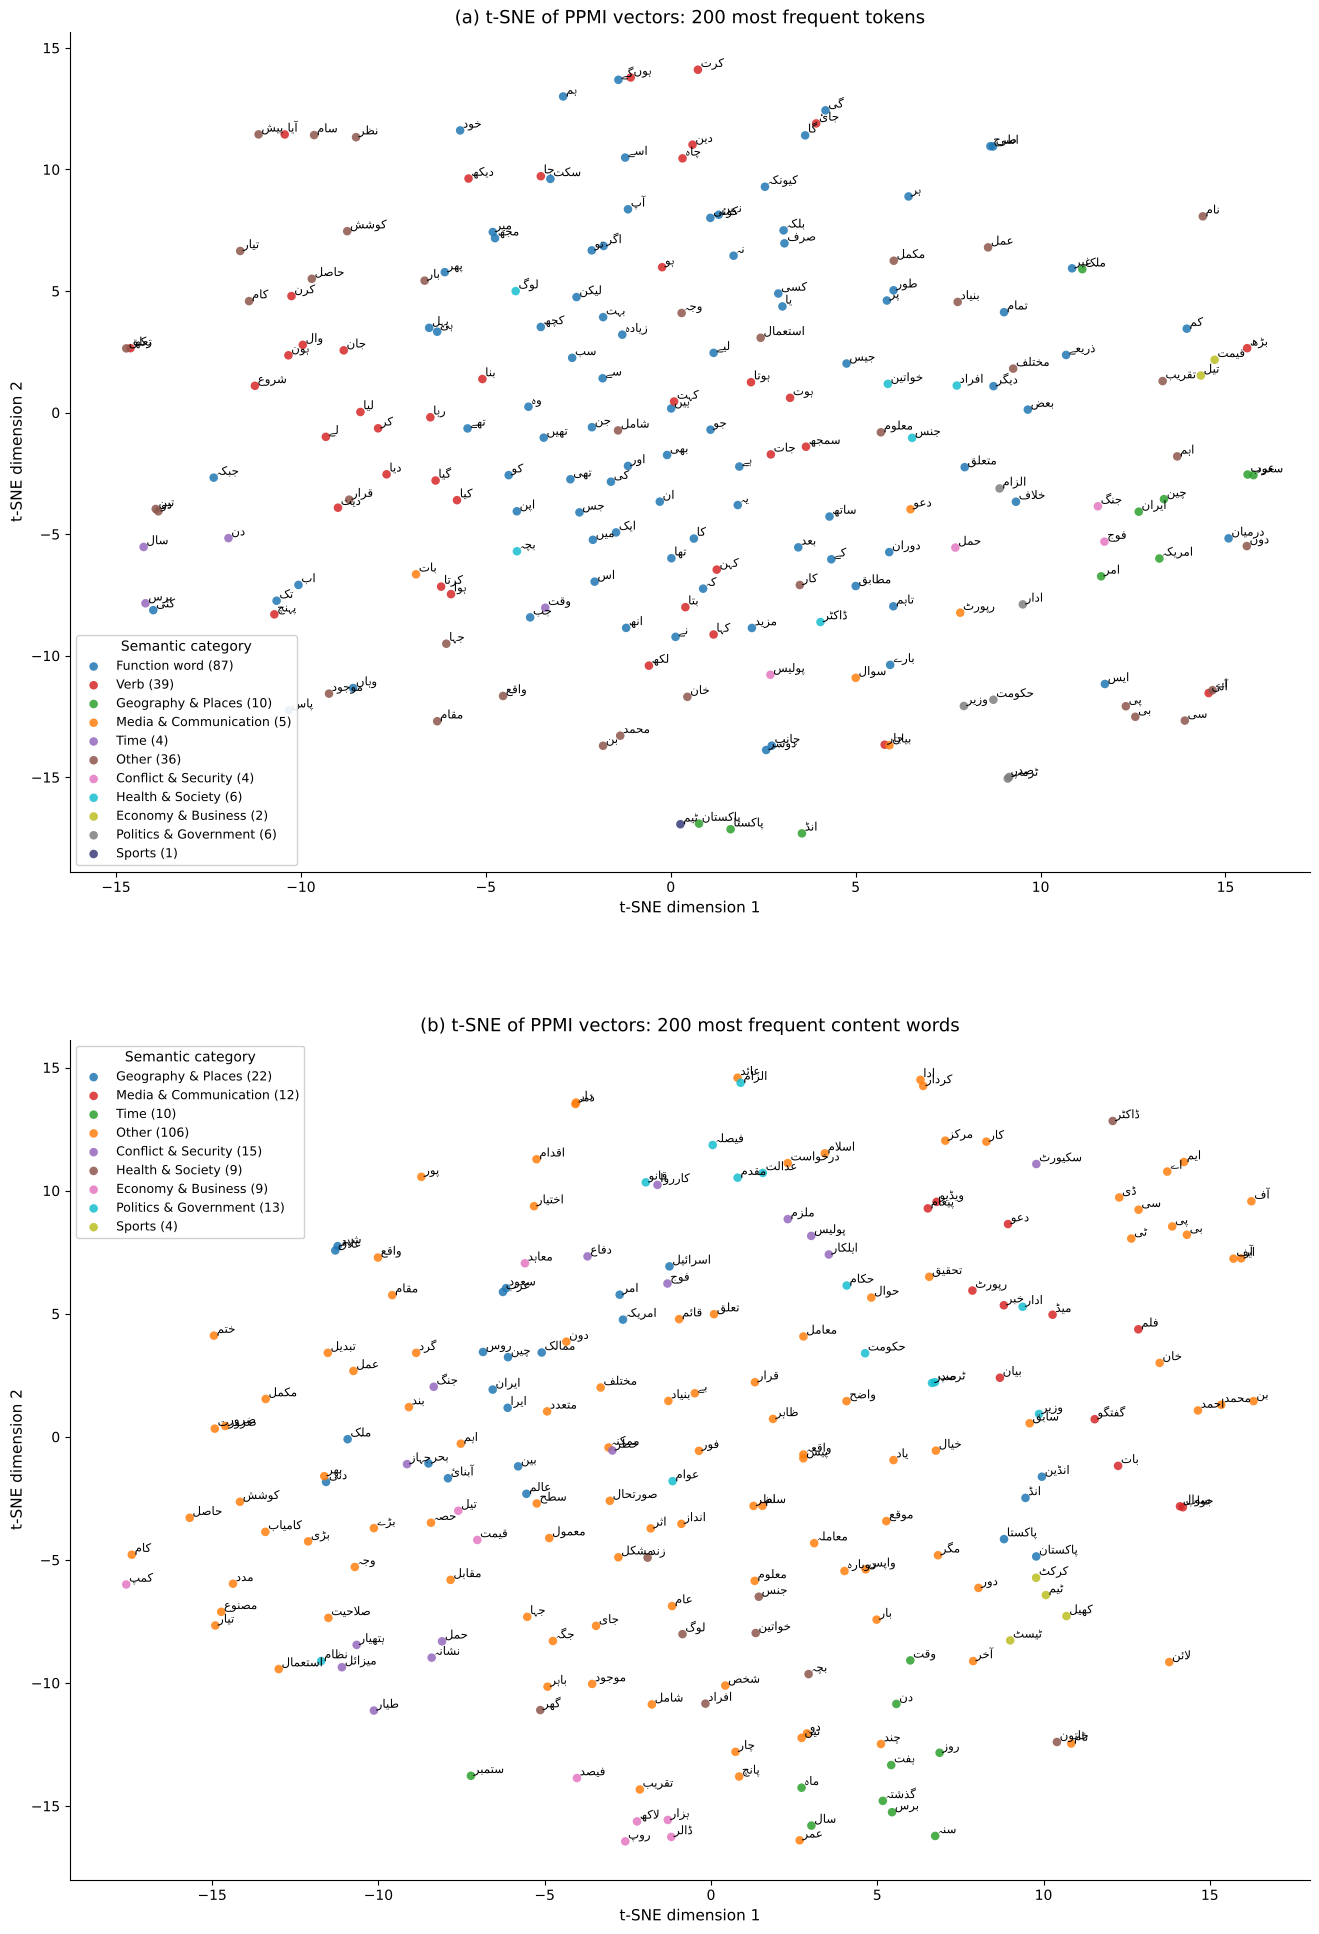

category counts (a): [('Function word', 87), ('Verb', 39), ('Other', 36), ('Geography & Places', 10), ('Health & Society', 6), ('Politics & Government', 6), ('Media & Communication', 5), ('Time', 4), ('Conflict & Security', 4), ('Economy & Business', 2), ('Sports', 1)]
category counts (b): [('Other', 106), ('Geography & Places', 22), ('Conflict & Security', 15), ('Politics & Government', 13), ('Media & Communication', 12), ('Time', 10), ('Health & Society', 9), ('Economy & Business', 9), ('Sports', 4)]


In [8]:
from embed_eval import tsne_2d, plot_tsne
from semantic_labels import category, TOKEN2CAT
freq_words = [w for w, _ in counts.most_common() if not is_symbol(w) and w in w2i]
top200 = freq_words[:200]
content200 = [w for w in freq_words if category(w) not in ("Function word", "Verb")][:200]
fig, axes = plt.subplots(2, 1, figsize=(16, 24))
for ax, words, title in [(axes[0], top200, "(a) t-SNE of PPMI vectors: 200 most frequent tokens"),
                         (axes[1], content200, "(b) t-SNE of PPMI vectors: 200 most frequent content words")]:
    Y = tsne_2d(P[[w2i[w] for w in words]])
    plot_tsne(Y, words, [category(w) for w in words], title, ax=ax)
savefig(fig, "tsne_ppmi.png"); plt.show()
print("category counts (a):", Counter(category(w) for w in top200).most_common())
print("category counts (b):", Counter(category(w) for w in content200).most_common())

**Top-5 nearest neighbours (cosine similarity of PPMI vectors) for 10 query words.** Candidate
neighbours are restricted to words that occur at least 5 times (the vectors of rarer words rest on
1–4 contexts and are unreliable); the same rule is used for every embedding in this notebook.

In [9]:
from eval_sets import PPMI_QUERIES, QUERY_WORDS, COND_QUERIES, MRR_PAIRS, ANALOGIES, cleaned, cleaned_analogies
from word2vec import encode_corpus, unigram_counts
clean_counts = unigram_counts(encode_corpus(sents, w2i), len(w2i) - 1)
ppmi_idx = CosineIndex(P, w2i, counts=clean_counts, min_count=5)
rows = []
for q in PPMI_QUERIES:
    nn = ppmi_idx.neighbours(q, 5)
    rows.append({"query": with_gloss(q), **{f"#{i+1}": f"{w} ({s:.2f})" for i, (w, s) in enumerate(nn)}})
RESULTS["ppmi_neighbours"] = {r["query"]: [r[f"#{i}"] for i in range(1, 6)] for r in rows}
pd.DataFrame(rows)

,query,#1,#2,#3,#4,#5
0,پاکستان (Pakistan),کرکٹ (0.24),ٹیم (0.20),پاکستا (0.17),کے (0.16),نے (0.16)
1,حکومت (government),وزیر (0.17),صدر (0.15),ریاس (0.15),طالبان (0.15),اقت (0.14)
2,عدالت (court),کورٹ (0.22),مقدم (0.21),درخواست (0.21),ملزمان (0.19),سپریم (0.18)
3,فوج (army),جنرل (0.17),اسرائیل (0.17),افواج (0.17),اہداف (0.17),ایران (0.17)
4,صحت (health),مند (0.22),ذہن (0.20),یاب (0.19),طبی (0.15),مسائل (0.14)
5,تعلیم (education),حاصل (0.15),لڑکی (0.14),یونیورسٹ (0.13),آمنہ (0.12),سکول (0.12)
6,کرکٹ (cricket),بورڈ (0.30),ٹیم (0.24),پاکستان (0.24),کوچ (0.20),کمنٹیٹر (0.20)
7,تیل (oil),خام (0.61),بیرل (0.35),برآمد (0.33),آبنائ (0.30),ہرمز (0.30)
8,پولیس (police),کوہاٹ (0.21),افسر (0.21),لائنز (0.18),ملزم (0.18),سٹی (0.18)
9,ایران (Iran),ایرا (0.24),تیل (0.20),ہرمز (0.19),جنگ (0.19),چین (0.19)


## 2.1 Skip-gram Word2Vec — implementation

* separate centre and context matrices **V**, **U** ∈ ℝ^(|V|×d), d = 100 (V ~ U(±0.5/d), U = 0 as in word2vec.c)
* noise distribution $P_n(w) \propto f(w)^{3/4}$, realised as a 10⁷-slot unigram table; **K = 10** noise words per positive pair
* loss $L = -\log\sigma(u_o^\top v_c) - \sum_{k=1}^{K} \log\sigma(-u_{w_k}^\top v_c)$ (binary cross-entropy)
* every (centre, context) pair with 1 ≤ |offset| ≤ **k = 5** inside a sentence; Adam (**η = 0.001**), batch **512**
* **15 epochs** (brief: ≥ 5). The number of epochs and whether to use word2vec's frequent-word
  sub-sampling were chosen *before* the final run on a separate development set of 180 analogies, disjoint
  from the 10 analogy tests reported below (`scripts/w2v_config_search.py`, results in
  `outputs/w2v_config_search.txt`): 15 epochs without sub-sampling had the best development top-3 accuracy.

In [10]:
from word2vec import build_noise_table, noise_distribution, skipgram_pairs, train_skipgram
sent_ids = encode_corpus(sents, w2i)
table = build_noise_table(clean_counts)
pn = noise_distribution(clean_counts); uni = clean_counts / clean_counts.sum()
emp = np.bincount(table, minlength=len(clean_counts)) / len(table)
print(f"noise table: {len(table):,} slots; max |empirical - f^0.75 distribution| = {np.abs(emp - pn).max():.2e}")
c_ids, o_ids = skipgram_pairs(sent_ids, C.W2V_WINDOW)
print(f"training pairs per epoch: {len(c_ids):,}  (from {sum(map(len, sent_ids)):,} tokens, window k={C.W2V_WINDOW})")
s0 = sents[0]
c0, o0 = skipgram_pairs([np.array([w2i.get(t, w2i[C.UNK]) for t in s0])], C.W2V_WINDOW)
centre_pos = 6
ctx = [i2w[o] for c, o in zip(c0, o0) if c == w2i.get(s0[centre_pos], w2i[C.UNK])]
print("example sentence:", " ".join(s0))
print(f"its {len(c0)} training pairs include, for centre '{s0[centre_pos]}' (position {centre_pos}):", ctx)
pd.DataFrame([{"word": w, "gloss": gloss(w), "count": int(clean_counts[w2i[w]]),
               "unigram P(w)": f"{uni[w2i[w]]:.5f}", "noise P_n(w)": f"{pn[w2i[w]]:.5f}",
               "P_n / P": round(pn[w2i[w]] / uni[w2i[w]], 2)}
              for w in ["کے", "ہے", "پاکستان", "حکومت", "کرکٹ", "معیشت", "ماسکو"]])

noise table: 10,000,000 slots; max |empirical - f^0.75 distribution| = 5.75e-08
training pairs per epoch: 3,893,618  (from 434,404 tokens, window k=5)
example sentence: پانچ سالہ سہیل احمد دیکھ سکت تھے کہ ان کے آس پاس موجود لوگ بیتاب سے ان کے بول کا انتظار کر رہا ہیں ۔
its 220 training pairs include, for centre 'تھے' (position 6): ['کہ', 'سکت', 'ان', 'دیکھ', 'کے', 'احمد', 'آس', 'سہیل', 'پاس', 'سالہ']


,word,gloss,count,unigram P(w),noise P_n(w),P_n / P
0,کے,of (genitive),18435,0.04244,0.01565,0.37
1,ہے,,8435,0.01942,0.00870,0.45
2,پاکستان,Pakistan,1058,0.00244,0.00183,0.75
3,حکومت,government,447,0.00103,0.00096,0.93
4,کرکٹ,cricket,202,0.00047,0.00053,1.14
5,معیشت,economy,41,0.00009,0.00016,1.70
6,ماسکو,Moscow,21,0.00005,0.00010,2.01


In [11]:
corpus_c3 = sents if RUN["w2v_limit"] is None else sents[:RUN["w2v_limit"]]
torch.set_num_threads(4)
res_c3 = train_skipgram(corpus_c3, w2i, dim=C.W2V_DIM, epochs=RUN["w2v_epochs"], subsample_t=C.W2V_SUBSAMPLE,
                        log_every=200, print_every=5000)
E_c3 = res_c3["embeddings"]
np.save(C.W2V_NPY, E_c3.astype(np.float32))
print(f"saved {C.W2V_NPY.relative_to(Path.cwd())}: 1/2(V+U), shape {E_c3.shape}; training took {res_c3['seconds']/60:.1f} min")

vocab=10,001  tokens=434,404  all pairs=3,893,618  d=100 k=5 K=10 batch=512 lr=0.001 subsample_t=None


    step   5000  loss (mean of last 200 batches) 3.1199


  epoch 1/15  pairs 3,893,618  mean loss 3.2571  (35s elapsed)


    step  10000  loss (mean of last 200 batches) 3.0398


    step  15000  loss (mean of last 200 batches) 3.0118


  epoch 2/15  pairs 3,893,618  mean loss 3.0315  (68s elapsed)


... (28 outputs left out)

    step 105000  loss (mean of last 200 batches) 2.7858


  epoch 14/15  pairs 3,893,618  mean loss 2.7729  (477s elapsed)


    step 110000  loss (mean of last 200 batches) 2.7656


  epoch 15/15  pairs 3,893,618  mean loss 2.7690  (510s elapsed)
saved embeddings/embeddings_w2v.npy: 1/2(V+U), shape (10001, 100); training took 8.5 min


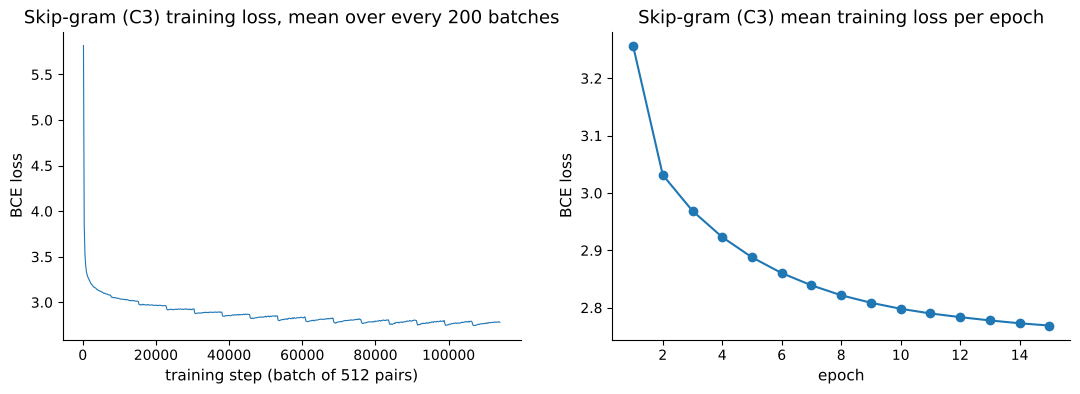

epoch losses: [3.2571, 3.0315, 2.9689, 2.9231, 2.8879, 2.8604, 2.8391, 2.8217, 2.8087, 2.7982, 2.7901, 2.7836, 2.7779, 2.7729, 2.769]


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(res_c3["log_steps"], res_c3["step_losses"], lw=0.8)
ax[0].set_title("Skip-gram (C3) training loss, mean over every 200 batches"); ax[0].set_xlabel("training step (batch of 512 pairs)"); ax[0].set_ylabel("BCE loss")
ax[1].plot(range(1, len(res_c3["epoch_losses"]) + 1), res_c3["epoch_losses"], marker="o")
ax[1].set_title("Skip-gram (C3) mean training loss per epoch"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("BCE loss")
savefig(fig, "w2v_loss_curve.png"); plt.show()
RESULTS["w2v_epoch_losses"] = res_c3["epoch_losses"]
print("epoch losses:", [round(x, 4) for x in res_c3["epoch_losses"]])

## 2.2 Evaluation

### Nearest neighbours and analogy

The eight Roman-Urdu query words of the brief are mapped to Urdu script and then through the A1
pipeline; two more words (cricket, oil) are added so that 10 query words are reported. Note
*Aabadi* (آبادی) becomes `آباد` after A1 stemming — the same token as the *-abad* of city names
(اسلام آباد، ایبٹ آباد), so its neighbours are dominated by places.

In [13]:
from eval_sets import EXTRA_QUERY_WORDS
idx_c3 = CosineIndex(E_c3, w2i, counts=clean_counts, min_count=5)
rows = []
for roman, urdu in {**QUERY_WORDS, **EXTRA_QUERY_WORDS}.items():
    q = cleaned(urdu)
    nn = idx_c3.neighbours(q, 10)
    rows.append({"query": roman, "Urdu": urdu, "A1 form": q, "freq": int(clean_counts[w2i[q]]),
                 "top-10 neighbours (cosine)": "، ".join(f"{w} {s:.2f}" for w, s in nn)})
RESULTS["w2v_neighbours"] = {r["query"]: r["top-10 neighbours (cosine)"] for r in rows}
pd.DataFrame(rows)

,query,Urdu,A1 form,freq,top-10 neighbours (cosine)
0,Pakistan,پاکستان,پاکستان,1058,کرکٹ 0.64، لیگ 0.62، بورڈ 0.61، بلتستان 0.60، گلگت 0.59، ہاک 0.57، انگلینڈ 0.57، شکست 0.56، انڈ 0.56، ویمنز 0.56
1,Hukumat,حکومت,حکومت,447,مطالبہ 0.58، پیٹرولیئم 0.55، انصاف 0.54، حکمران 0.54، ریاس 0.54، پیٹرولیم 0.54، طالبان 0.54، مدھیہ 0.52، حکوم 0.51، محکمہ 0.51
2,Adalat,عدالت,عدالت,178,جج 0.66، درخواست 0.64، مقدم 0.63، استدع 0.62، چٹھہ 0.57، سزا 0.57، اپیل 0.57، کورٹ 0.56، وکیل 0.56، دائر 0.56
3,Maeeshat,معیشت,معیشت,41,معاش 0.60، قلت 0.59، زر 0.58، قیمت 0.58، مہنگا 0.57، اثر 0.56، تیل 0.55، عالم 0.53، سکڑ 0.53، ایرا 0.52
4,Fauj,فوج,فوج,398,کمانڈر 0.63، عسکر 0.61، کمان 0.58، افواج 0.58، اسرائیل 0.57، کارروائی 0.56، اتحاد 0.56، بنگلہ 0.55، اہداف 0.55، دیش 0.54
5,Sehat,صحت,صحت,114,یاب 0.61، ذہن 0.59، شوگر 0.57، کمال 0.55، مسائل 0.55، مند 0.53، تولید 0.53، معائ 0.53، بگڑ 0.52، طبی 0.51
6,Taleem,تعلیم,تعلیم,89,انجینیئرنگ 0.56، طالبعلم 0.52، سکول 0.51، رقص 0.50، پڑھا 0.49، ملازمت 0.48، حاصل 0.47، لڑکی 0.47، متحد 0.46، پریشر 0.46
7,Aabadi,آبادی,آباد,152,اسلام 0.83، لاہور 0.59، شمائلہ 0.57، کابل 0.54، دارالحکومت 0.54، تھانہ 0.53، نعیم 0.52، راولپنڈ 0.51، کورٹ 0.51، ہاد 0.50
8,Cricket,کرکٹ,کرکٹ,202,بورڈ 0.77، ٹیم 0.66، انگلینڈ 0.64، پاکستان 0.64، رمیز 0.61، شائقین 0.59، میچز 0.59، کمنٹیٹر 0.59، کارکرد 0.58، کپتان 0.58
9,Tail (oil),تیل,تیل,467,خام 0.89، بیرل 0.72، سپلا 0.72، ترسیل 0.71، برآمد 0.70، ذخائر 0.70، آبنائ 0.69، رسد 0.68، ہرمز 0.67، پیداوار 0.67


**Analogy tests** `a : b :: c : ?` answered with $v(b)-v(a)+v(c)$ (unit vectors, cosine; a, b, c
excluded). The 10 tests were fixed in advance (`src/eval_sets.py`): each covers a sensible relation
and each of its two word pairs co-occurs at least 3 times in the corpus. A test counts as **correct
when the expected word is among the reported top-3 candidates** (top-1 is shown as well).

In [14]:
from embed_eval import run_analogies, mean_reciprocal_rank
an_rows = run_analogies(idx_c3, cleaned_analogies(), k=3)
tab = pd.DataFrame([{"relation": r["relation"], "analogy": f"{r['a']} : {r['b']} :: {r['c']} : ?",
                     "expected": with_gloss(r["expected"]),
                     "top-3 candidates": "، ".join(f"{w} {s:.2f}" for w, s in r["top"]),
                     "top-1": "✓" if r["top1"] else "✗", "in top-3": "✓" if r["top3"] else "✗"}
                    for r in an_rows])
n1, n3 = sum(r["top1"] for r in an_rows), sum(r["top3"] for r in an_rows)
RESULTS["analogies"] = {"top1": n1, "top3": n3, "rows": tab.to_dict("records")}
print(f"correct: {n3}/10 (expected word in top-3), {n1}/10 at top-1")
tab

correct: 5/10 (expected word in top-3), 4/10 at top-1


,relation,analogy,expected,top-3 candidates,top-1,in top-3
0,country : capital,روس : ماسکو :: انڈ : ?,دہل (Delhi (<-دہلی)),پریس 0.55، ڈے 0.55، ٹوڈ 0.51,✗,✗
1,country : leader,امریکہ : ٹرمپ :: روس : ?,پوتن (Putin),ولادیمیر 0.63، پوتن 0.61، صدر 0.58,✗,✓
2,country : leader,امریکہ : ٹرمپ :: اسرائیل : ?,نیتن (Netanyahu (<-نیتن یاہو)),ڈونلڈ 0.60، اوسوف 0.56، صدر 0.56,✗,✗
3,country : demonym,پاکستان : پاکستا :: انڈ : ?,انڈین (Indian),انڈین 0.50، کثیر 0.48، بحریہ 0.48,✓,✓
4,first name : surname,عمران : خان :: شہباز : ?,شریف (Sharif),شریف 0.76، وزیراعظم 0.65، اعظم 0.54,✓,✓
5,first name : surname,ڈونلڈ : ٹرمپ :: نریندر : ?,مود (Modi (<-مودی)),مود 0.74، وینس 0.54، اوسوف 0.53,✓,✓
6,institution : professional,عدالت : جج :: ہسپتال : ?,ڈاکٹر (doctor),پمز 0.60، وارڈ 0.58، گاندھ 0.56,✗,✗
7,male : female,مرد : عورت :: بھا : ?,بہن (sister),منتظم 0.49، فوت 0.47، آپ 0.47,✗,✗
8,armed group : territory,حماس : غزہ :: طالبان : ?,افغانستان (Afghanistan),ازا 0.51، منسلک 0.49، صوب 0.48,✗,✗
9,commodity : unit,تیل : بیرل :: پیٹرول : ?,لیٹر (litre),لیٹر 0.81، فی 0.72، روپ 0.68,✓,✓


**Assessment.** The skip-gram embeddings clearly capture meaningful *topical and functional* relations: the neighbours of عدالت (court) are جج (judge), درخواست (petition), مقدمے (case), استدعا (plea), سزا (sentence), اپیل (appeal), کورٹ, وکیل (lawyer) and دائر (filed); فوج (army) sits next to کمانڈر, عسکری, کمان and افواج; معیشت (economy) next to معاشی, قلت (shortage), زر (as in افراطِ زر, inflation), قیمت (price) and مہنگائی; and the two extra words behave the same way (کرکٹ → بورڈ، ٹیم، میچز، کپتان; تیل → خام، بیرل، برآمد، ذخائر، پیداوار) — all shown in A1-stemmed form in the table. Five of the ten analogy tests are solved within the top-3 (four of them at rank 1): country→leader, country→demonym, first name→surname and commodity→unit — relations that are repeated many times in this news corpus — whereas relations attested only a handful of times (capitals, male/female kinship, institution→professional, armed group→territory) fail. With only 434k tokens the vectors also absorb corpus-specific collocations: پاکستان is closest to cricket words (کرکٹ، لیگ، بورڈ، ہاکی) because "Pakistan cricket board / league / women's team" are frequent phrases, and the A1 stemmer conflates آبادی (population) with the *-abad* of city names, so the neighbours of *Aabadi* are places (اسلام آباد، لاہور، کابل، راولپنڈی).

### Four-condition comparison

| ID | Condition | Description |
|---|---|---|
| C1 | PPMI baseline | PPMI-weighted co-occurrence vectors (Section 1.2) |
| C2 | Skip-gram on `raw.txt` | the unprocessed corpus: sentence split + whitespace tokens, no normalisation / lemmatization / stemming |
| C3 | Skip-gram on `cleaned.txt` | the model above |
| C4 | Skip-gram, d = 200 | C3 with doubled embedding dimension |

C2 and C4 use exactly the C3 training settings. MRR is computed on 20 manually labelled
related word pairs (query → related word): the rank of the related word among all candidates by
cosine similarity to the query; for C2 the pairs are looked up in their raw surface spelling.

In [15]:
raw_sents = flatten(load_raw_sentences_unprocessed())
w2i_raw = build_vocab(raw_sents)
raw_counts = unigram_counts(encode_corpus(raw_sents, w2i_raw), len(w2i_raw) - 1)
print(f"raw corpus: {len(raw_sents):,} sentences, {sum(map(len, raw_sents)):,} tokens, "
      f"{len(token_counts(raw_sents)):,} types (cleaned: {len(counts):,})")
corpus_c2 = raw_sents if RUN["w2v_limit"] is None else raw_sents[:RUN["w2v_limit"]]
res_c2 = train_skipgram(corpus_c2, w2i_raw, dim=C.W2V_DIM, epochs=RUN["w2v_epochs"], subsample_t=C.W2V_SUBSAMPLE, verbose=True)
res_c4 = train_skipgram(corpus_c3, w2i, dim=200, epochs=RUN["w2v_epochs"], subsample_t=C.W2V_SUBSAMPLE, verbose=True)
print(f"C2 trained in {res_c2['seconds']/60:.1f} min, C4 in {res_c4['seconds']/60:.1f} min")

raw corpus: 15,016 sentences, 406,977 tokens, 19,423 types (cleaned: 10,943)


vocab=10,001  tokens=406,977  all pairs=3,619,508  d=100 k=5 K=10 batch=512 lr=0.001 subsample_t=None


  epoch 1/15  pairs 3,619,508  mean loss 3.2690  (26s elapsed)


  epoch 2/15  pairs 3,619,508  mean loss 3.0099  (54s elapsed)


  epoch 3/15  pairs 3,619,508  mean loss 2.9296  (81s elapsed)


  epoch 4/15  pairs 3,619,508  mean loss 2.8728  (106s elapsed)


... (22 outputs left out)

  epoch 12/15  pairs 3,893,618  mean loss 2.7015  (852s elapsed)


  epoch 13/15  pairs 3,893,618  mean loss 2.6946  (922s elapsed)


  epoch 14/15  pairs 3,893,618  mean loss 2.6886  (995s elapsed)


  epoch 15/15  pairs 3,893,618  mean loss 2.6838  (1063s elapsed)
C2 trained in 6.6 min, C4 in 17.7 min


In [16]:
conds = {"C1 PPMI": (CosineIndex(P, w2i, counts=clean_counts, min_count=5), "clean"),
         "C2 skip-gram raw": (CosineIndex(res_c2["embeddings"], w2i_raw, counts=raw_counts, min_count=5), "raw"),
         "C3 skip-gram cleaned": (idx_c3, "clean"),
         "C4 skip-gram d=200": (CosineIndex(res_c4["embeddings"], w2i, counts=clean_counts, min_count=5), "clean")}
def form(word, kind): return cleaned(word) if kind == "clean" else word
nn_rows, mrr_rows = [], []
for name, (idx, kind) in conds.items():
    for q in COND_QUERIES:
        qq = form(q, kind)
        nn = idx.neighbours(qq, 5) if qq in idx.w2i else []
        nn_rows.append({"condition": name, "query": qq, "top-5 neighbours": "، ".join(w for w, _ in nn)})
    ranks = []
    for a, b in MRR_PAIRS:
        qa, qb = form(a, kind), form(b, kind)
        ranks.append(idx.rank_of(qa, qb) if qa in idx.w2i and qb in idx.w2i else None)
    rr = [1.0 / r if r else 0.0 for r in ranks]
    mrr_rows.append({"condition": name, "MRR": round(float(np.mean(rr)), 4),
                     "pairs found": sum(r is not None for r in ranks),
                     "median rank": int(np.median([r for r in ranks if r])),
                     "related word ranked 1st": sum(r == 1 for r in ranks),
                     "in top-10": sum(1 for r in ranks if r and r <= 10)})
mrr_df = pd.DataFrame(mrr_rows)
RESULTS["mrr"] = mrr_df.to_dict("records")
display(pd.DataFrame(nn_rows).pivot(index="query", columns="condition", values="top-5 neighbours"))
mrr_df

condition,C1 PPMI,C2 skip-gram raw,C3 skip-gram cleaned,C4 skip-gram d=200
query,,,,
حکومت,وزیر، صدر، ریاس، طالبان، اقت,نظامِ، پیٹرولیئم، تحریکِ، انخلا، طالبان,مطالبہ، پیٹرولیئم، انصاف، حکمران، ریاس,مطالبہ، انخل، پیٹرولیئم، طالبان، وزیر
صحت,مند، ذہن، یاب، طبی، مسائل,ذہنی، یاب، مند، مسائل، معائنے,یاب، ذہن، شوگر، کمال، مسائل,یاب، شوگر، کمال، ذہن، مند
عدالت,کورٹ، مقدم، درخواست، ملزمان، سپریم,مقدمے، جج، دائر، استدعا، درخواست,جج، درخواست، مقدم، استدع، چٹھہ,استدع، مقدم، جج، سزا، درخواست
فوج,جنرل، اسرائیل، افواج، اہداف، ایران,دیشی، اسرائیلی، بنگلہ، ابوبکر، فوجی,کمانڈر، عسکر، کمان، افواج، اسرائیل,کمانڈر، ابوبکر، کمان، اہداف، افواج
پاکستان,کرکٹ، ٹیم، پاکستا، کے، نے,ہاکی، کرکٹ، لیگ، ویمنز، انگلینڈ,کرکٹ، لیگ، بورڈ، بلتستان، گلگت,کرکٹ، بلتستان، گلگت، انگلینڈ، لیگ


,condition,MRR,pairs found,median rank,related word ranked 1st,in top-10
0,C1 PPMI,0.3419,20,5,4,14
1,C2 skip-gram raw,0.2358,20,10,2,11
2,C3 skip-gram cleaned,0.2903,20,9,3,11
3,C4 skip-gram d=200,0.2354,20,6,1,12


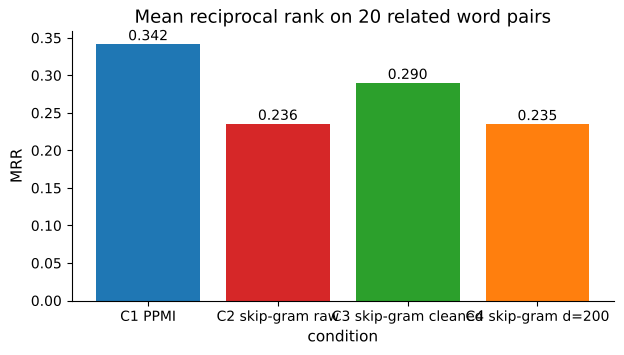

,query,related,C1 PPMI,C2 skip-gram raw,C3 skip-gram cleaned,C4 skip-gram d=200
0,حکومت (government),وزیر (minister),1,9,17,5
1,عدالت (court),جج (judge),6,2,1,3
2,فوج (army),جنرل (general),1,11,13,6
3,کرکٹ (cricket),ٹیم (team),2,3,2,3
4,تیل (oil),گیس (gas),12,24,13,16
5,ہسپتال (hospital),ڈاکٹر (doctor),4,22,25,38
6,پولیس (police),ملزم (accused),4,7,9,8
7,ایران (Iran),تہران (Tehran),28,21,1,4
8,اسرائیل (Israel),غزہ (Gaza),2,2,3,3
9,میزائل (missile),ڈرون (drone),9,3,4,2


In [17]:
pair_tab = pd.DataFrame([{"query": with_gloss(cleaned(a)), "related": with_gloss(cleaned(b)),
                          **{name: (idx.rank_of(form(a, k), form(b, k)) if form(a, k) in idx.w2i and form(b, k) in idx.w2i else "n/a")
                             for name, (idx, k) in conds.items()}} for a, b in MRR_PAIRS])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(mrr_df["condition"], mrr_df["MRR"], color=PALETTE[:4])
for i, v in enumerate(mrr_df["MRR"]): ax.text(i, v + 0.005, f"{v:.3f}", ha="center")
ax.set_title("Mean reciprocal rank on 20 related word pairs"); ax.set_xlabel("condition"); ax.set_ylabel("MRR")
savefig(fig, "mrr_conditions.png"); plt.show()
pair_tab

**Discussion.** On the 20 labelled pairs the PPMI baseline (C1) has the highest MRR (0.342; 4 related words ranked first, median rank 5), followed by skip-gram on the cleaned corpus (C3, 0.290), while skip-gram on raw text (C2, 0.236) and the 200-dimensional model (C4, 0.235) are lowest. With only 0.43 M tokens, explicit count statistics are a strong baseline: frequent, tightly co-occurring pairs (government–minister, army–general, Russia–Ukraine, Imran–Khan) are ranked first by PPMI directly, whereas skip-gram must learn them through stochastic optimisation from the same few contexts. Preprocessing clearly helps the neural model: C3 beats C2, and C2's neighbour lists are split over inflected, izafat-marked or punctuation-attached variants (نظامِ، تحریکِ، اسرائیلی، دیشی، فوجی) — the raw text has 19,423 types against 10,943 after cleaning, so each surface form gets fewer training contexts and the 10k vocabulary covers less of the text. Doubling the dimension does not help: C4 reaches a lower training loss than C3 (2.684 vs 2.769) but a lower MRR, i.e. the extra capacity is spent fitting this small corpus rather than producing better similarities. Among the neural models the best embeddings are therefore C3 (d = 100 on the cleaned corpus), and PPMI is best overall on this small test set; note that with 20 pairs a single rank change moves the MRR by up to 0.05, so the C1–C3 gap is indicative rather than conclusive.

# Part 2 — Sequence Labelling: POS Tagging & NER

## 3. Dataset preparation

1. **500 sentences** are drawn at random (seed 42) from `cleaned.txt`: **100 from each of the 5 topic
   categories** (so ≥ 100 from each of ≥ 3 categories); sentences with 5–50 tokens, no duplicates.
2. **POS** — rule-based tagger (`src/pos_tagger.py`) built on the A1 lemmatizer/stemmer and a hand-crafted
   lexicon (`src/pos_lexicon.py`): lookup of the surface form, then of its **A1 lemma**, then of its **A1 stem**
   (only stems that are unambiguous in the lexicon), then morphology with the A1 suffix inventory (verbal
   endings on a known verb root → VERB, plural/abstract endings → NOUN, nisba *-ی* on a known noun → ADJ),
   then context rules for ambiguous function words (میں PRON/POST, کی POST/VERB, کیا PRON/VERB, لیے POST/VERB,
   یہ/وہ/اس/ان DET/PRON, ہو/جا/رہ VERB/AUX, …) and for unknown words (before a case marker or light verb, after a
   determiner → NOUN, else UNK). The brief says "12 tags" but lists 11; **AUX** (auxiliaries ہے، تھا، گا، رہا،
   سکتا، چکا, passive جا) was added as the 12th tag.
3. **NER** — seed gazetteer (`src/ner_gazetteer.py`) matched on the original words, longest match first, plus a
   given-name + name-part pattern for persons; BIO tags projected onto the cleaned tokens.
4. **Split** 70/15/15 inside every topic (stratified): 350 / 75 / 75 sentences.

In [18]:
from pos_tagger import lexicon_entry_counts
from ner_gazetteer import coverage
from part2_data import build_and_save, label_distribution, read_conll, SPLITS
lex = lexicon_entry_counts()
display(pd.DataFrame([lex], index=["hand-crafted lexicon entries"]))
display(pd.DataFrame([coverage()], index=["gazetteer entries"]))
splits = build_and_save()
print({s: len(v) for s, v in splits.items()}, "| sentences per topic and split:")
pd.DataFrame({s: Counter(x["topic"] for x in splits[s]) for s in SPLITS}).loc[C.CATEGORIES]

,NOUN,VERB (lemmas),VERB (all forms),ADJ,ADV,PRON,DET,CONJ,POST,AUX,NUM
hand-crafted lexicon entries,823,252,3998,399,253,63,30,34,72,75,60


,Pakistani persons,foreign persons,locations,organisations,misc
gazetteer entries,86,44,121,71,56


{'train': 350, 'val': 75, 'test': 75} | sentences per topic and split:


,train,val,test
Politics,70,15,15
Sports,70,15,15
Economy,70,15,15
International,70,15,15
Health & Society,70,15,15


In [19]:
for x in splits["train"][:3]:
    print(f"[{x['topic']}] article {x['article_number']}")
    print("  POS:", " ".join(f"{t}/{p}" for t, p in zip(x["tokens"], x["pos"])))
    print("  NER:", " ".join(f"{t}/{n}" for t, n in zip(x["tokens"], x["ner"]) if n != "O") or "(no entity)")

[Politics] article 240
  POS: یہاں/ADV تک/POST کہ/CONJ مدھیہ/UNK پردیش/UNK ہائ/NOUN کورٹ/NOUN نے/POST اس/DET معامل/NOUN کا/POST ازخود/ADV نوٹس/NOUN لیا/VERB ۔/PUNC
  NER: ہائ/B-ORG کورٹ/I-ORG
[Politics] article 22
  POS: یہاں/ADV سپریم/ADJ کورٹ/NOUN اور/CONJ ریاس/ADJ ہائ/NOUN کورٹس/NOUN میں/POST ایس/DET معاملہ/NOUN اٹھا/VERB کے/POST بھرپور/ADJ مواقع/NOUN موجود/ADJ ہیں/AUX ۔/PUNC ‘/PUNC
  NER: سپریم/B-ORG کورٹ/I-ORG
[Politics] article 198
  POS: انھ/PRON نے/POST دعو/NOUN کیا/VERB کہ/CONJ السید/UNK نومبر/NOUN کے/POST انتخاب/NOUN میں/POST ریپبلکن/UNK امیدوار/UNK مائیک/UNK راجرز/NOUN سے/POST ہار/VERB جای/AUX گے/AUX ۔/PUNC
  NER: (no entity)


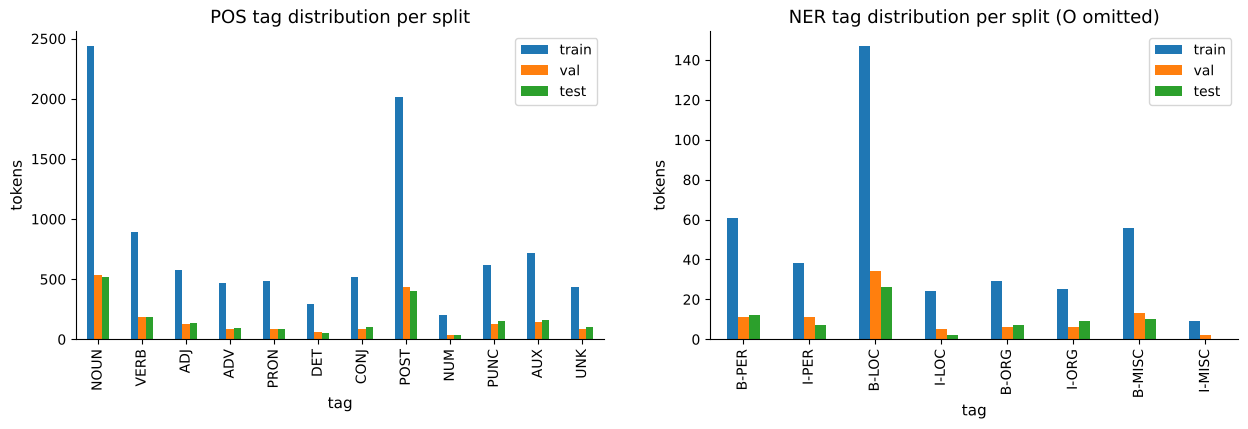

,train,val,test,total
NOUN,2439,538,520,3497
VERB,891,188,186,1265
ADJ,579,130,133,842
ADV,465,84,91,640
PRON,483,82,88,653
DET,295,60,56,411
CONJ,514,85,104,703
POST,2011,432,405,2848
NUM,201,36,38,275
PUNC,619,124,154,897


,train,val,test,total
O,9255,1899,1963,13117
B-PER,61,11,12,84
I-PER,38,11,7,56
B-LOC,147,34,26,207
I-LOC,24,5,2,31
B-ORG,29,6,7,42
I-ORG,25,6,9,40
B-MISC,56,13,10,79
I-MISC,9,2,0,11


In [20]:
pos_dist = pd.DataFrame(label_distribution(splits, "pos")).reindex(C.POS_TAGS).fillna(0).astype(int)
ner_dist = pd.DataFrame(label_distribution(splits, "ner")).reindex(C.NER_TAGS).fillna(0).astype(int)
pos_dist["total"] = pos_dist.sum(axis=1); ner_dist["total"] = ner_dist.sum(axis=1)
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
pos_dist[list(SPLITS)].plot.bar(ax=ax[0]); ax[0].set_title("POS tag distribution per split"); ax[0].set_xlabel("tag"); ax[0].set_ylabel("tokens")
ner_dist.drop(index="O")[list(SPLITS)].plot.bar(ax=ax[1]); ax[1].set_title("NER tag distribution per split (O omitted)"); ax[1].set_xlabel("tag"); ax[1].set_ylabel("tokens")
savefig(fig, "part2_label_distribution.png"); plt.show()
RESULTS["pos_distribution"] = pos_dist.to_dict(); RESULTS["ner_distribution"] = ner_dist.to_dict()
display(pos_dist); ner_dist

## 4. BiLSTM sequence labeller

`src/seq_models.py`: embedding (initialised with the C3 Word2Vec vectors, `<PAD>` row = 0) → **2-layer
bidirectional LSTM** (hidden 128 per direction, **dropout 0.5 between the layers**) → per-token
representation $h_t=[\overrightarrow{h_t};\overleftarrow{h_t}]$ → linear layer.
**POS:** softmax + cross-entropy. **NER:** **CRF** with a learnable tag-transition matrix (plus start/end
scores), trained with the forward algorithm and decoded with **Viterbi**. Variable-length batches are
packed; padded positions carry label −100 (ignored by cross-entropy) and mask = 0 (skipped by the CRF),
so **padding never contributes to the loss** (unit-tested). Adam (η = 10⁻³, weight decay 10⁻⁴), batch 16,
**early stopping on validation F1 with patience 5** (POS: token macro-F1; NER: entity F1 from
conlleval; an exact F1 tie counts as progress only if the validation loss fell), best epoch restored.

Every configuration is trained with 3 seeds (42, 7, 123). For each task the embedding mode (frozen or
fine-tuned) with the higher **mean validation F1 over the seeds** is selected; its seed-42 model is saved and
analysed in Section 5, and mean ± std over the seeds is given wherever configurations are compared.

In [21]:
from train_seq import SeqConfig, encode_data, train, run_eval
from seq_models import BiLSTMTagger
emb = np.vstack([E_c3, np.zeros((1, E_c3.shape[1]), dtype=np.float32)])     # + <PAD> row
pad_idx = w2i[C.PAD]
assert emb.shape[0] == len(w2i) and pad_idx == emb.shape[0] - 1
DATA2 = {}
for task, tags in (("pos", C.POS_TAGS), ("ner", C.NER_TAGS)):
    t2i = {t: i for i, t in enumerate(tags)}
    DATA2[task] = {s: encode_data(*read_conll(C.DATA / f"{task}_{s}.conll"), w2i, t2i) for s in SPLITS}
unk_rate = np.mean([i == w2i[C.UNK] for s in DATA2["pos"]["train"].x for i in s])
print(f"embedding matrix {emb.shape} (C3 + <PAD>); <UNK> rate in Part-2 train tokens: {100*unk_rate:.2f}%")
print(BiLSTMTagger(len(C.NER_TAGS), emb.shape[0], 100, pretrained=emb, pad_idx=pad_idx, use_crf=True))

embedding matrix (10002, 100) (C3 + <PAD>); <UNK> rate in Part-2 train tokens: 0.23%
BiLSTMTagger(
  (emb): Embedding(10002, 100, padding_idx=10001)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.5, bidirectional=True)
  (out): Linear(in_features=256, out_features=9, bias=True)
  (crf): CRF()
)


In [22]:
TAGSETS = {"pos": C.POS_TAGS, "ner": C.NER_TAGS}
EXPERIMENTS = {   # name -> (task, config overrides)
    "POS frozen":            ("pos", dict(freeze=True)),
    "POS fine-tuned":        ("pos", dict(freeze=False)),
    "POS A1 unidirectional": ("pos", dict(bidirectional=False)),
    "POS A2 no dropout":     ("pos", dict(dropout=0.0)),
    "POS A3 random init":    ("pos", dict(pretrained=False)),
    "NER frozen":            ("ner", dict(freeze=True)),
    "NER fine-tuned (CRF)":  ("ner", dict(freeze=False)),
    "NER A1 unidirectional": ("ner", dict(bidirectional=False)),
    "NER A2 no dropout":     ("ner", dict(dropout=0.0)),
    "NER A3 random init":    ("ner", dict(pretrained=False)),
    "NER A4 softmax (no CRF)": ("ner", dict(use_crf=False)),
}
MAIN = ["POS frozen", "POS fine-tuned", "NER frozen", "NER fine-tuned (CRF)"]
RUNS = {}
t_all = time.time()
for seed in RUN["seeds"]:
    for name, (task, over) in EXPERIMENTS.items():
        cfg = SeqConfig(task=task, name=name, seed=seed, max_epochs=RUN["seq_max_epochs"], **over)
        verbose = seed == 42 and name in MAIN
        if verbose: print(f"=== {name} (seed {seed}) ===")
        r = train(cfg, DATA2[task]["train"], DATA2[task]["val"], TAGSETS[task], emb, pad_idx, verbose=verbose)
        _, test_pred, test_f1 = run_eval(r["model"], DATA2[task]["test"], cfg, pad_idx, TAGSETS[task])
        r.update(test_pred=test_pred, test_f1=test_f1)
        RUNS[(name, seed)] = r
        print(f"{name:26s} seed {seed:3d}: best epoch {r['best_epoch']:2d}/{r['epochs_run']:2d}  "
              f"val F1 {r['best_val_f1']:6.2f}  test F1 {test_f1:6.2f}  "
              f"({np.mean(r['history']['epoch_seconds']):.1f}s/epoch)")
print(f"all {len(RUNS)} runs finished in {(time.time()-t_all)/60:.1f} min")

=== POS frozen (seed 42) ===


  [POS frozen] epoch  1  train loss 2.2443  val loss 2.0710  val F1   3.55  *


  [POS frozen] epoch  2  train loss 2.0291  val loss 1.8235  val F1  20.63  *


  [POS frozen] epoch  3  train loss 1.7102  val loss 1.4137  val F1  31.69  *


  [POS frozen] epoch  4  train loss 1.2972  val loss 1.0710  val F1  47.38  *


  [POS frozen] epoch  5  train loss 1.0549  val loss 0.9095  val F1  54.37  *


... (141 outputs left out)

NER A1 unidirectional      seed 123: best epoch 49/54  val F1  66.67  test F1  54.21  (0.9s/epoch)


NER A2 no dropout          seed 123: best epoch 33/38  val F1  69.03  test F1  72.38  (1.5s/epoch)


NER A3 random init         seed 123: best epoch 27/32  val F1  60.00  test F1  60.00  (1.5s/epoch)


NER A4 softmax (no CRF)    seed 123: best epoch 26/31  val F1  58.41  test F1  58.25  (1.3s/epoch)
all 33 runs finished in 21.4 min


In [23]:
def ms(vals): return f"{np.mean(vals):.2f} ± {np.std(vals):.2f}"
summary = []
for name, (task, _) in EXPERIMENTS.items():
    rs = [RUNS[(name, s)] for s in RUN["seeds"]]
    summary.append({"model": name, "metric": "macro-F1" if task == "pos" else "entity F1",
                    "val F1 (seed 42)": round(RUNS[(name, 42)]["best_val_f1"], 2),
                    "test F1 (seed 42)": round(RUNS[(name, 42)]["test_f1"], 2),
                    "val F1 mean ± std": ms([r["best_val_f1"] for r in rs]),
                    "test F1 mean ± std": ms([r["test_f1"] for r in rs]),
                    "best epoch (seeds)": [r["best_epoch"] for r in rs]})
summary_df = pd.DataFrame(summary)
RESULTS["seq_summary"] = summary_df.to_dict("records")
print("Validation F1 of the frozen and fine-tuned embedding modes (Section 4):")
summary_df[summary_df.model.isin(MAIN)]

Validation F1 of the frozen and fine-tuned embedding modes (Section 4):


,model,metric,val F1 (seed 42),test F1 (seed 42),val F1 mean ± std,test F1 mean ± std,best epoch (seeds)
0,POS frozen,macro-F1,82.36,82.23,82.24 ± 0.44,81.85 ± 0.47,"[26, 24, 39]"
1,POS fine-tuned,macro-F1,89.48,87.81,89.15 ± 0.35,88.57 ± 0.55,"[13, 15, 12]"
5,NER frozen,entity F1,49.09,39.18,47.99 ± 2.91,39.34 ± 3.38,"[30, 32, 22]"
6,NER fine-tuned (CRF),entity F1,69.64,64.76,70.36 ± 3.35,69.90 ± 3.79,"[32, 36, 30]"


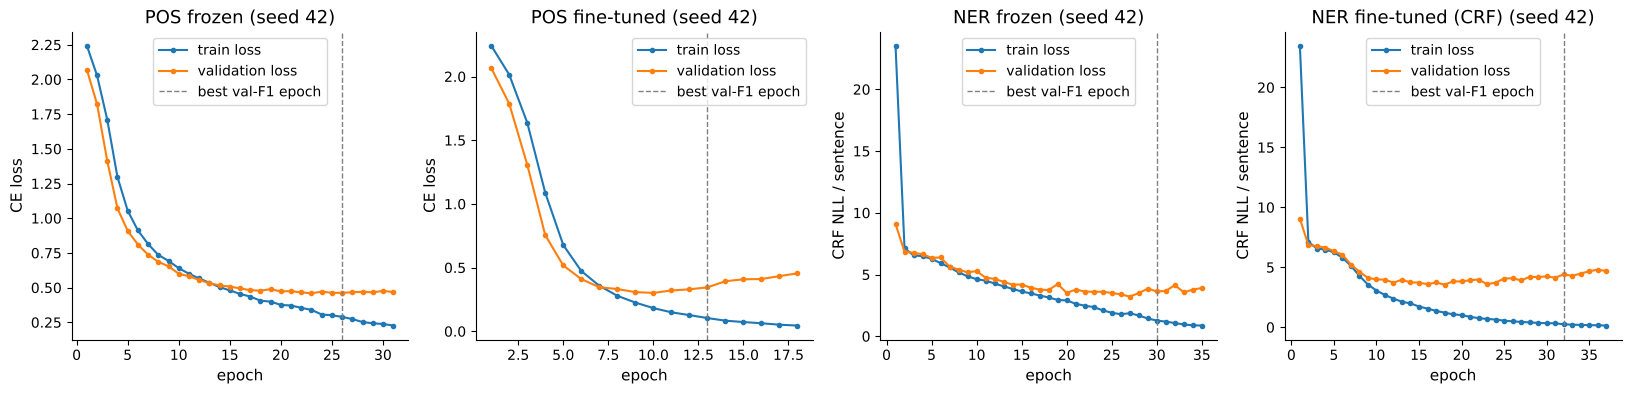

mean validation F1 over seeds: {'POS frozen': 82.24, 'POS fine-tuned': 89.15, 'NER frozen': 47.99, 'NER fine-tuned (CRF)': 70.36}
selected embedding mode per task (highest mean validation F1): {'pos': 'POS fine-tuned', 'ner': 'NER fine-tuned (CRF)'}


In [24]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, name in zip(axes, MAIN):
    h = RUNS[(name, 42)]["history"]; ep = range(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss"], marker=".", label="train loss"); ax.plot(ep, h["val_loss"], marker=".", label="validation loss")
    ax.axvline(RUNS[(name, 42)]["best_epoch"], color="grey", ls="--", lw=1, label="best val-F1 epoch")
    ax.set_title(name + " (seed 42)"); ax.set_xlabel("epoch"); ax.set_ylabel("CE loss" if name.startswith("POS") else "CRF NLL / sentence"); ax.legend()
savefig(fig, "part2_training_curves.png"); plt.show()
mean_val = {n: float(np.mean([RUNS[(n, s)]["best_val_f1"] for s in RUN["seeds"]])) for n in MAIN}
best_mode = {t: max([n for n in MAIN if n.lower().startswith(t)], key=lambda n: mean_val[n]) for t in ("pos", "ner")}
print("mean validation F1 over seeds:", {n: round(v, 2) for n, v in mean_val.items()})
print("selected embedding mode per task (highest mean validation F1):", best_mode)

In [25]:
for task, fname in (("pos", "bilstm_pos.pt"), ("ner", "bilstm_ner.pt")):
    name = best_mode[task]; r = RUNS[(name, 42)]
    torch.save({"state_dict": r["model"].state_dict(), "config": r["config"], "tags": TAGSETS[task],
                "pad_idx": pad_idx, "vocab": "embeddings/word2idx.json", "val_f1": r["best_val_f1"],
                "test_f1": r["test_f1"], "best_epoch": r["best_epoch"]}, C.MODELS / fname)
    print(f"saved models/{fname}  <- {name} (seed 42)")

saved models/bilstm_pos.pt  <- POS fine-tuned (seed 42)
saved models/bilstm_ner.pt  <- NER fine-tuned (CRF) (seed 42)


## 5. Evaluation

### 5.1 POS tagging (test set, fine-tuned model, seed 42)

In [26]:
from metrics import accuracy, macro_f1, confusion_matrix, per_class_prf, most_confused_pairs
from part2_eval import confused_examples, entity_errors
pos_name = best_mode["pos"]
pos_gold = DATA2["pos"]["test"].tags; pos_pred = RUNS[(pos_name, 42)]["test_pred"]
g = [t for s in pos_gold for t in s]; p = [t for s in pos_pred for t in s]
acc, mf1 = 100 * accuracy(g, p), 100 * macro_f1(g, p)
RESULTS["pos_test"] = {"model": pos_name, "accuracy": acc, "macro_f1": mf1, "tokens": len(g)}
print(f"{pos_name}: token accuracy {acc:.2f}%, macro-F1 {mf1:.2f} over {len(set(g) | set(p))} tags ({len(g):,} test tokens)")
prf = per_class_prf(g, p, C.POS_TAGS)
pd.DataFrame(prf).T.round(3)

POS fine-tuned: token accuracy 89.78%, macro-F1 87.81 over 12 tags (2,036 test tokens)


,precision,recall,f1,support
NOUN,0.866,0.869,0.868,520.0
VERB,0.872,0.914,0.892,186.0
ADJ,0.709,0.842,0.770,133.0
ADV,0.816,0.879,0.847,91.0
PRON,0.882,0.932,0.906,88.0
DET,0.895,0.911,0.903,56.0
CONJ,0.971,0.952,0.961,104.0
POST,0.980,0.985,0.983,405.0
NUM,1.000,0.974,0.987,38.0
PUNC,1.000,1.000,1.000,154.0


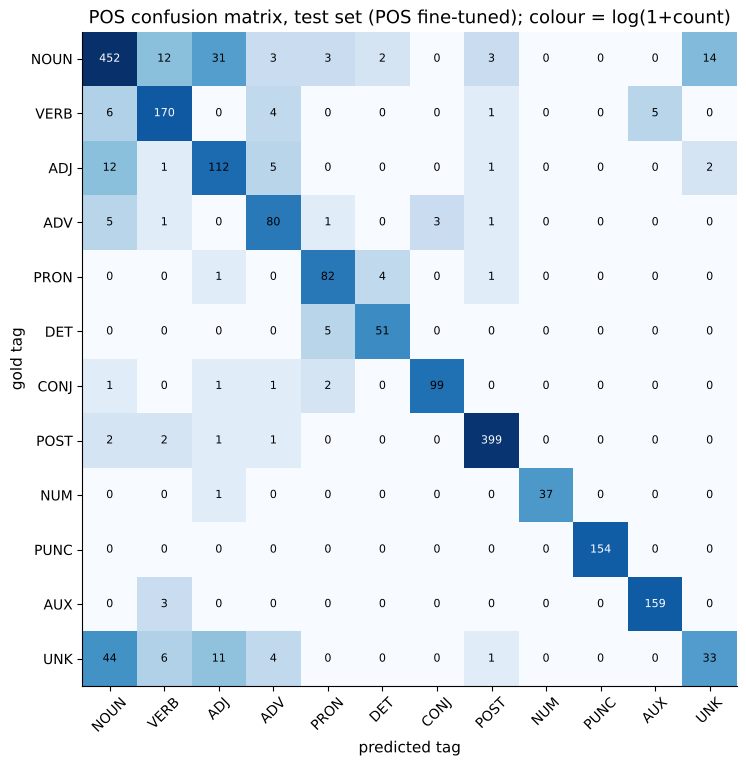

3 most confused tag pairs (both directions): [('NOUN', 'UNK', 58), ('NOUN', 'ADJ', 43), ('NOUN', 'VERB', 18)]


In [27]:
cm = confusion_matrix(g, p, C.POS_TAGS)
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(np.log1p(cm), cmap="Blues")
for i in range(len(C.POS_TAGS)):
    for j in range(len(C.POS_TAGS)):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 3 else "black")
ax.set_xticks(range(12)); ax.set_xticklabels(C.POS_TAGS, rotation=45); ax.set_yticks(range(12)); ax.set_yticklabels(C.POS_TAGS)
ax.set_xlabel("predicted tag"); ax.set_ylabel("gold tag"); ax.set_title(f"POS confusion matrix, test set ({pos_name}); colour = log(1+count)")
savefig(fig, "pos_confusion_matrix.png"); plt.show()
pairs3 = most_confused_pairs(cm, C.POS_TAGS, 3)
RESULTS["pos_confused_pairs"] = pairs3
print("3 most confused tag pairs (both directions):", pairs3)

In [28]:
test_tokens = DATA2["pos"]["test"].tokens
for a, b, n in pairs3:
    print(f"--- {a} <-> {b}: {n} confusions ---")
    for ex in confused_examples(test_tokens, pos_gold, pos_pred, (a, b), k=2):
        print("  •", ex)

--- NOUN <-> UNK: 58 confusions ---
  • یہ کوئی آسان فیصلہ نہیں تھا لیکن ہمی اس سفر کو [انجام gold=NOUN pred=UNK] دین کی ضرورت محسوس ہوا ۔ ‘
  • ہمار [صحافی gold=NOUN pred=UNK] ، جن میں پاکستان میں تعین مقام عملہ بھی شامل ہے ، کو ملک کے تمام علاق میں سفر کرن کی اجازت ہون چاہ تاکہ وہ رونم ہون وال واقعہ کی بروقت کوریج کر سکی اور عام شہری کی آواز سن سکی ۔ ‘
--- NOUN <-> ADJ: 43 confusions ---
  • اس کے علاوہ کمیٹ نظام میں [بہتر gold=ADJ pred=NOUN] کے لیے ضرور اصلاح اور اپن تحقیق کے نتائج دو ہفت کے اندر پیش کرے گی ۔
  • یونیورسٹ آف ساؤتھمپٹن میں قانون کی لیکچرر ڈاکٹر [جون gold=NOUN pred=ADJ] مہو نے سے گفتگو کرتا ہوا کہا کہ ان کے خیال میں یہ [پیشکش gold=NOUN pred=ADJ] قانو ہو گی ، اگرچہ ان کے مطابق [سیاست gold=NOUN pred=ADJ] دان ’ عام طور پر اسے اتن واضح انداز میں نہیں کرتا ۔ ‘
--- NOUN <-> VERB: 18 confusions ---
  • اس کے علاوہ کمیٹ نظام میں بہتر کے لیے ضرور [اصلاح gold=NOUN pred=VERB] اور اپن تحقیق کے نتائج دو ہفت کے اندر پیش کرے گی ۔
  • میڈ میں یہ سرخی ظاہر کرتا ہیں کہ ٹرمپ کو مشکل سیا

**Why these tags are confused.** (1) **NOUN ↔ UNK** (58 errors; 44 of the 99 gold-UNK tokens are predicted NOUN, 14 gold nouns are predicted UNK). In the silver annotation, UNK is what the rule-based tagger assigns to words that are in neither the lexicon nor covered by a morphology or context rule — rare nouns, names, transliterated English words — while the same kind of word becomes NOUN as soon as it stands before a case marker. The label therefore depends on rules the BiLSTM only sees indirectly: it calls most gold-UNK words NOUN (often linguistically right) and occasionally predicts UNK for real nouns such as انجام (completion) or صحافی (journalist); UNK is the weakest class (F1 0.45). (2) **NOUN ↔ ADJ** (43; 31 of them gold nouns predicted ADJ). The A1 stemmer strips the nisba suffix *-ی* that separates many adjectives from their nouns (سیاسی → سیاس, بہتری → بہتر), so the cleaned token alone is ambiguous, and names or nouns in adjectival positions (جون, پیشکش, سیاست in سیاست دان) are pulled towards ADJ; some gold labels are themselves wrong: بہتر in "نظام میں بہتری کے لیے" is the noun *improvement*, but the tagger's stem fallback labelled it ADJ, so here the model's NOUN is the correct tag. (3) **NOUN ↔ VERB** (18). Urdu conjunct verbs (noun + کرنا/ہونا) put nouns directly before verbal material, and stemming makes some nouns look like verb roots (سامنا *facing* → سام before ہے; اصلاح *reform*).

In [29]:
rows = []
for name in ("POS frozen", "POS fine-tuned"):
    accs, f1s = [], []
    for s in RUN["seeds"]:
        pp = [t for x in RUNS[(name, s)]["test_pred"] for t in x]
        accs.append(100 * accuracy(g, pp)); f1s.append(100 * macro_f1(g, pp))
    rows.append({"embedding mode": name, "val macro-F1 (seed 42)": round(RUNS[(name, 42)]["best_val_f1"], 2),
                 "test accuracy (seed 42)": round(accs[0], 2), "test macro-F1 (seed 42)": round(f1s[0], 2),
                 "test accuracy mean ± std": ms(accs), "test macro-F1 mean ± std": ms(f1s),
                 "epochs to best (seed 42)": RUNS[(name, 42)]["best_epoch"]})
pos_modes = pd.DataFrame(rows); RESULTS["pos_modes"] = pos_modes.to_dict("records")
pos_modes

,embedding mode,val macro-F1 (seed 42),test accuracy (seed 42),test macro-F1 (seed 42),test accuracy mean ± std,test macro-F1 mean ± std,epochs to best (seed 42)
0,POS frozen,82.36,84.33,82.23,84.05 ± 0.27,81.85 ± 0.47,26
1,POS fine-tuned,89.48,89.78,87.81,90.19 ± 0.29,88.57 ± 0.55,13


### 5.2 NER (test set, entity level, conlleval)

The test predictions are written in CoNLL format and scored with the **original `conlleval` Perl script**
(`tools/conlleval.pl`, Tjong Kim Sang, version 2004-01-26); `src/conlleval.py` is a port used for the
per-type table and during training (the two agree exactly — unit-tested).

In [30]:
import conlleval
ner_name = best_mode["ner"]
ner_tokens, ner_gold = DATA2["ner"]["test"].tokens, DATA2["ner"]["test"].tags
ner_pred = RUNS[(ner_name, 42)]["test_pred"]
print(f"conlleval.pl on {ner_name} (seed 42):")
print(conlleval.run_perl(ner_tokens, ner_gold, ner_pred))
ev = conlleval.evaluate(ner_gold, ner_pred)
tab = pd.DataFrame(ev["per_type"]).T[["precision", "recall", "f1", "gold", "found", "correct"]]
tab.loc["overall"] = [ev["precision"], ev["recall"], ev["f1"], ev["gold_phrases"], ev["found_phrases"], ev["correct_phrases"]]
RESULTS["ner_test"] = {"model": ner_name, **{k: ev[k] for k in ("precision", "recall", "f1")}, "per_type": ev["per_type"]}
tab.round(2)

conlleval.pl on NER fine-tuned (CRF) (seed 42):
processed 2036 tokens with 55 phrases; found: 50 phrases; correct: 34.
accuracy:  98.23%; precision:  68.00%; recall:  61.82%; FB1:  64.76
              LOC: precision:  73.33%; recall:  84.62%; FB1:  78.57  30
             MISC: precision:  66.67%; recall:  60.00%; FB1:  63.16  9
              ORG: precision:  25.00%; recall:  14.29%; FB1:  18.18  4
              PER: precision:  71.43%; recall:  41.67%; FB1:  52.63  7



,precision,recall,f1,gold,found,correct
LOC,73.33,84.62,78.57,26.0,30.0,22.0
MISC,66.67,60.00,63.16,10.0,9.0,6.0
ORG,25.00,14.29,18.18,7.0,4.0,1.0
PER,71.43,41.67,52.63,12.0,7.0,5.0
overall,68.00,61.82,64.76,55.0,50.0,34.0


In [31]:
rows = []
for name in ("NER fine-tuned (CRF)", "NER A4 softmax (no CRF)"):
    evs = [conlleval.evaluate(ner_gold, RUNS[(name, s)]["test_pred"]) for s in RUN["seeds"]]
    rows.append({"output layer": "CRF + Viterbi" if "CRF" in name and "no CRF" not in name else "softmax (per-token argmax)",
                 "P (seed 42)": round(evs[0]["precision"], 2), "R (seed 42)": round(evs[0]["recall"], 2),
                 "F1 (seed 42)": round(evs[0]["f1"], 2), "F1 mean ± std": ms([e["f1"] for e in evs]),
                 "P mean": round(np.mean([e["precision"] for e in evs]), 2), "R mean": round(np.mean([e["recall"] for e in evs]), 2),
                 **{f"{t} F1 (seed 42)": round(evs[0]["per_type"].get(t, {}).get("f1", 0.0), 2) for t in ("PER", "LOC", "ORG", "MISC")}})
crf_df = pd.DataFrame(rows); RESULTS["ner_crf_vs_softmax"] = crf_df.to_dict("records")
print("Softmax model (seed 42), conlleval.pl:")
print(conlleval.run_perl(ner_tokens, ner_gold, RUNS[("NER A4 softmax (no CRF)", 42)]["test_pred"]))
crf_df

Softmax model (seed 42), conlleval.pl:
processed 2036 tokens with 55 phrases; found: 47 phrases; correct: 34.
accuracy:  98.18%; precision:  72.34%; recall:  61.82%; FB1:  66.67
              LOC: precision:  71.88%; recall:  88.46%; FB1:  79.31  32
             MISC: precision:  83.33%; recall:  50.00%; FB1:  62.50  6
              ORG: precision:   0.00%; recall:   0.00%; FB1:   0.00  0
              PER: precision:  66.67%; recall:  50.00%; FB1:  57.14  9



,output layer,P (seed 42),R (seed 42),F1 (seed 42),F1 mean ± std,P mean,R mean,PER F1 (seed 42),LOC F1 (seed 42),ORG F1 (seed 42),MISC F1 (seed 42)
0,CRF + Viterbi,68.00,61.82,64.76,69.90 ± 3.79,74.23,66.06,52.63,78.57,18.18,63.16
1,softmax (per-token argmax),72.34,61.82,66.67,62.39 ± 3.44,66.52,58.79,57.14,79.31,0.00,62.50


In [32]:
fps, fns = entity_errors(ner_tokens, ner_gold, ner_pred)
print(f"{len(fps)} false-positive and {len(fns)} false-negative entities on the test set ({ner_name}, seed 42)")
fp_df = pd.DataFrame(fps[:5]); fn_df = pd.DataFrame(fns[:5])
RESULTS["ner_fp"] = fps[:5]; RESULTS["ner_fn"] = fns[:5]
print("False positives (predicted entity not in the gold annotation):"); display(fp_df)
print("False negatives (gold entity not predicted exactly):"); fn_df

16 false-positive and 21 false-negative entities on the test set (NER fine-tuned (CRF), seed 42)
False positives (predicted entity not in the gold annotation):


,sent,span,pred_type,gold,context
0,6,مصطف,ORG,"[(مصطف نواز, PER)]",مصطف نواز کھوکھر نے اس
1,6,نواز,PER,"[(مصطف نواز, PER)]",مصطف نواز کھوکھر نے اس شق
2,23,فاطمہ ثنا,PER,"[(فاطمہ, PER)]",بات کا ادراک کپتان فاطمہ ثنا کو بھی ہے جنھ
3,27,سعود,MISC,[],روز کھیل کے دوران سعود شکیل کی <NUM> رنز
4,29,پاکستان,LOC,"[(پاکستان کرکٹ بورڈ, ORG)]",وال سابق کرکٹرز اور پاکستان کرکٹ بورڈ سے بات


False negatives (gold entity not predicted exactly):


,sent,span,gold_type,pred,context
0,6,مصطف نواز,PER,"[(نواز, PER), (مصطف, ORG)]",مصطف نواز کھوکھر نے اس شق
1,9,خیبر پختونخو,LOC,[],فرزانہ علی خیبر پختونخو کے شہر پشاور میں
2,9,پشاور,LOC,[],خیبر پختونخو کے شہر پشاور میں آج نیوز سے
3,14,انور ابراہیم,PER,[],اس پر انور ابراہیم کا کہن تھا کہ
4,21,جیو نیوز,ORG,[],طلال چوہدر نے ’ جیو نیوز ‘ سے گفتگو کرتا


**Error analysis (fine-tuned BiLSTM-CRF, seed 42).** A span with the right tokens but the wrong type or boundaries counts as both a false positive and a false negative in conlleval.

*False positives*
1. **مصطف → ORG** (gold: مصطفیٰ نواز, PER). مصطف (the A1 stem of مصطفیٰ) never occurs in the 350 training sentences, so the model splits the unseen name into an ORG piece and a PER piece.
2. **نواز → PER** — the second half of the same name (نواز is I-PER twice in training); the span is too short.
3. **فاطمہ ثنا → PER** (gold: فاطمہ only). Here the *model is right*: Fatima Sana is Pakistan's women's cricket captain; the silver label is incomplete because ثنا (also 'praise') was deliberately left out of the given-name list.
4. **سعود → MISC** (gold O). This is the cricketer Saud Shakeel, but the A1 stemmer maps سعودی (Saudi) and the name سعود to the same token, which is MISC (5×) or part of LOC سعودی عرب (5×) in training, so the model reads 'Saudi'. The gold label is wrong too (should be PER): he is not in the gazetteer.
5. **پاکستان → LOC** inside پاکستان کرکٹ بورڈ (gold ORG). پاکستان is LOC in 31 of its 33 training occurrences and the three-token organisation name was seen once, so the model tags the country and misses the organisation.

*False negatives*
1. **مصطفیٰ نواز (PER)** — wrong boundaries/types, see FP 1–2.
2. **خیبر پختونخوا (LOC)** and 3. **پشاور (LOC)** in "فرزانہ علی خیبر پختونخوا کے شہر پشاور میں ..." — none of these tokens occurs in the training split, and the reporter-byline context (name + place + 'Aaj News') is unlike the training sentences.
4. **انور ابراہیم (PER)** — Malaysia's prime minister; both tokens are unseen in training and only 61 person entities are available to learn person contexts from.
5. **جیو نیوز (ORG)** — Geo News: unseen tokens inside quotation marks, and ORG is the rarest type (29 training entities; test F1 18.2).

**Overall:** the errors come mostly from (a) entities whose tokens never occur in the 350 training sentences, where the model must rely on context it has seen too few examples of, (b) the A1 stemmer merging different words (سعود), and (c) noise in the silver annotation itself (incomplete names, people missing from the gazetteer) — part of the measured error is annotation error, not model error.

### 5.3 Ablation study

Each ablation changes one thing relative to the fine-tuned model of Section 4 and is trained on the same
split with the same 3 seeds: **A1** unidirectional (forward) 2-layer LSTM, **A2** no dropout,
**A3** random embedding initialisation (instead of C3 Word2Vec), **A4** softmax output instead of the CRF (NER).

In [33]:
abl = []
for task, base in (("pos", "POS fine-tuned"), ("ner", "NER fine-tuned (CRF)")):
    base_f1 = [RUNS[(base, s)]["test_f1"] for s in RUN["seeds"]]
    for name, (t, _) in EXPERIMENTS.items():
        if t != task or not (name == base or " A" in name): continue
        f1s = [RUNS[(name, s)]["test_f1"] for s in RUN["seeds"]]
        vf = [RUNS[(name, s)]["best_val_f1"] for s in RUN["seeds"]]
        abl.append({"task": task.upper(), "model": name, "val F1 mean ± std": ms(vf), "test F1 mean ± std": ms(f1s),
                    "Δ test F1 vs full model": "—" if name == base else f"{np.mean(f1s) - np.mean(base_f1):+.2f}",
                    "test F1 per seed": [round(x, 1) for x in f1s]})
abl_df = pd.DataFrame(abl); RESULTS["ablations"] = abl_df.to_dict("records")
abl_df

,task,model,val F1 mean ± std,test F1 mean ± std,Δ test F1 vs full model,test F1 per seed
0,POS,POS fine-tuned,89.15 ± 0.35,88.57 ± 0.55,—,"[87.8, 88.9, 89.0]"
1,POS,POS A1 unidirectional,83.50 ± 0.27,83.13 ± 0.80,-5.44,"[83.9, 83.5, 82.0]"
2,POS,POS A2 no dropout,88.71 ± 0.09,88.23 ± 0.52,-0.34,"[87.8, 87.9, 89.0]"
3,POS,POS A3 random init,85.86 ± 0.27,84.34 ± 0.56,-4.24,"[84.1, 85.1, 83.8]"
4,NER,NER fine-tuned (CRF),70.36 ± 3.35,69.90 ± 3.79,—,"[64.8, 71.2, 73.8]"
5,NER,NER A1 unidirectional,44.81 ± 15.46,46.37 ± 5.54,-23.53,"[42.6, 42.3, 54.2]"
6,NER,NER A2 no dropout,68.23 ± 2.00,70.96 ± 4.59,+1.06,"[64.8, 75.7, 72.4]"
7,NER,NER A3 random init,58.82 ± 1.06,58.48 ± 4.73,-11.42,"[63.4, 52.1, 60.0]"
8,NER,NER A4 softmax (no CRF),61.75 ± 2.48,62.39 ± 3.44,-7.51,"[66.7, 62.3, 58.3]"


**Findings.** **A1 (unidirectional)** is the most damaging change: −5.4 macro-F1 for POS and −23.5 F1 for NER. Urdu is head-final, so the disambiguating evidence usually comes *after* a token — whether کی is the genitive or the verb *did* is decided by a following auxiliary, and یہ/اس are determiners only if a noun follows — and for NER a forward-only model has to decide B-PER/B-LOC at the first token of an entity without seeing the surname, postposition or "… کے شہر" context that follows (its validation F1 also varies wildly across seeds, ±15.5). **A2 (no dropout)** has no measurable effect (POS −0.3, NER +1.1, both well within one standard deviation): with only 350 sentences, early stopping on validation F1 already limits over-fitting, so dropout between the two LSTM layers neither helps nor hurts here. **A3 (random initialisation)** costs 4.2 POS and 11.4 NER points: the C3 vectors bring distributional knowledge from the whole 434k-token corpus (which words behave like names, places, function words or verbs) that 350 labelled sentences cannot provide on their own. **A4 (softmax instead of CRF)** lowers mean NER F1 by 7.5 (62.4 ± 3.4 vs 69.9 ± 3.8), through both precision (66.5 vs 74.2) and recall (58.8 vs 66.1): per-token argmax decides every tag independently and ignores which tag sequences are valid (e.g. I-PER after O), whereas the CRF learns transition scores and decodes the best whole sequence with Viterbi. On seed 42 alone the softmax model happens to score higher (66.7 vs 64.8) — single runs on 55 test entities are noisy, which is why every comparison is reported over three seeds.

# Part 3 — Transformer Encoder for Topic Classification

## 6. Dataset preparation

Every article (labels from Section 0.1) is represented by the token ids of its first **256** tokens in
`cleaned.txt` (shorter articles are padded with `<PAD>`), using the shared 10k vocabulary. Split 70/15/15
**stratified by category** (seed 42).

article length: min 190, median 1601, max 4997 tokens; 249 of 250 articles truncated to 256, 1 padded


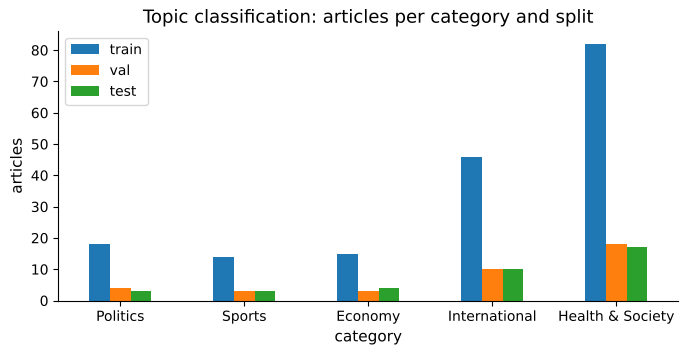

,train,val,test,total
Politics,18,4,3,25
Sports,14,3,3,20
Economy,15,3,4,22
International,46,10,10,66
Health & Society,82,18,17,117


In [34]:
from part3 import build_dataset, subset, make_transformer, train_classifier, evaluate, BiLSTMClassifier
data3 = build_dataset(w2i)
d3 = pd.DataFrame({s: Counter(C.CATEGORIES[i] for i in data3["y"][data3["split"] == s]) for s in SPLITS}).loc[C.CATEGORIES]
d3["total"] = d3.sum(axis=1)
L = data3["full_lengths"]
print(f"article length: min {L.min()}, median {int(np.median(L))}, max {L.max()} tokens; "
      f"{(L > C.MAX_LEN).sum()} of 250 articles truncated to {C.MAX_LEN}, {(L < C.MAX_LEN).sum()} padded")
RESULTS["part3_distribution"] = d3.to_dict()
fig, ax = plt.subplots(figsize=(8, 3.5))
d3[list(SPLITS)].plot.bar(ax=ax); ax.set_title("Topic classification: articles per category and split")
ax.set_xlabel("category"); ax.set_ylabel("articles"); plt.xticks(rotation=0)
savefig(fig, "part3_class_distribution.png"); plt.show()
d3

## 7. Transformer encoder (from scratch, `src/transformer.py`)

* `ScaledDotProductAttention` — softmax(QKᵀ/√d_k)V with an optional padding mask; returns output **and** weights
* `MultiHeadSelfAttention` — **h = 4** heads, d_model = 128, **separate** W_Q, W_K, W_V (128→32) per head, shared W_O (128→128)
* `PositionwiseFeedForward` — Linear(128→512) → ReLU → Dropout → Linear(512→128)
* `SinusoidalPositionalEncoding` — fixed `register_buffer`, added to the input embeddings
* `EncoderBlock` ×4 with **Pre-LayerNorm**: x ← x + Dropout(MHA(LN(x))); x ← x + Dropout(FFN(LN(x)))
* learned **[CLS]** vector prepended to every sequence → final LayerNorm → MLP **128 → 64 → 5**

Training: **AdamW** (η = 5×10⁻⁴, weight decay 0.01), **cosine schedule with 50 linear warm-up steps**,
**20 epochs**, batch 16, dropout 0.1, cross-entropy. The checkpoint of the epoch with the best validation
accuracy is used for testing.

In [35]:
torch.manual_seed(C.SEED)
tf_model = make_transformer(w2i)
print(tf_model)
n_params = sum(p.numel() for p in tf_model.parameters())
print(f"trainable parameters: {n_params:,} (of which embeddings {tf_model.embed.weight.numel():,}); "
      f"positional encoding is a buffer: {'pos.pe' in dict(tf_model.named_buffers())}, "
      f"in parameters: {any('pe' in n for n, _ in tf_model.named_parameters())}")

TransformerClassifier(
  (embed): Embedding(10002, 128, padding_idx=10001)
  (pos): SinusoidalPositionalEncoding()
  (drop): Dropout(p=0.1, inplace=False)
  (blocks): ModuleList(
    (0-3): 4 x EncoderBlock(
      (ln1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): MultiHeadSelfAttention(
        (W_q): ModuleList(
          (0-3): 4 x Linear(in_features=128, out_features=32, bias=True)
        )
        (W_k): ModuleList(
          (0-3): 4 x Linear(in_features=128, out_features=32, bias=True)
        )
        (W_v): ModuleList(
          (0-3): 4 x Linear(in_features=128, out_features=32, bias=True)
        )
        (W_o): Linear(in_features=128, out_features=128, bias=True)
        (attention): ScaledDotProductAttention(
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
      (ln2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (ffn): PositionwiseFeedForward(
        (lin1): Linear(in_features=128, out_f

In [36]:
res_tf = train_classifier(tf_model, data3, "transformer", RUN["tf_epochs"], C.TF_LR, C.TF_WEIGHT_DECAY, C.TF_BATCH, seed=C.SEED)
torch.save({"state_dict": res_tf["model"].state_dict(), "best_epoch": res_tf["best_epoch"],
            "categories": C.CATEGORIES, "pad_idx": w2i[C.PAD], "vocab": "embeddings/word2idx.json"},
           C.MODELS / "transformer_cls.pt")
print(f"best validation accuracy {res_tf['best_val_acc']:.1f}% at epoch {res_tf['best_epoch']}; saved models/transformer_cls.pt")

  [transformer] epoch  1  train loss 1.6046 acc  24.6  |  val loss 1.3953 acc  47.4 macro-F1  12.9  (3.9s)


  [transformer] epoch  2  train loss 1.3805 acc  46.9  |  val loss 1.3503 acc  47.4 macro-F1  12.9  (3.8s)


  [transformer] epoch  3  train loss 1.3734 acc  47.4  |  val loss 1.3410 acc  47.4 macro-F1  12.9  (3.9s)


  [transformer] epoch  4  train loss 1.3549 acc  46.9  |  val loss 1.3385 acc  47.4 macro-F1  12.9  (4.3s)


  [transformer] epoch  5  train loss 1.3647 acc  46.9  |  val loss 1.3365 acc  47.4 macro-F1  12.9  (3.7s)


  [transformer] epoch  6  train loss 1.3514 acc  46.3  |  val loss 1.3249 acc  47.4 macro-F1  12.9  (4.5s)


... (10 outputs left out)

  [transformer] epoch 17  train loss 0.2900 acc  94.3  |  val loss 0.8481 acc  68.4 macro-F1  61.0  (4.0s)


  [transformer] epoch 18  train loss 0.2794 acc  94.9  |  val loss 0.8398 acc  68.4 macro-F1  62.2  (4.3s)


  [transformer] epoch 19  train loss 0.2726 acc  94.3  |  val loss 0.8457 acc  68.4 macro-F1  60.1  (4.9s)


  [transformer] epoch 20  train loss 0.2850 acc  94.3  |  val loss 0.8463 acc  68.4 macro-F1  60.1  (4.3s)
best validation accuracy 68.4% at epoch 18; saved models/transformer_cls.pt


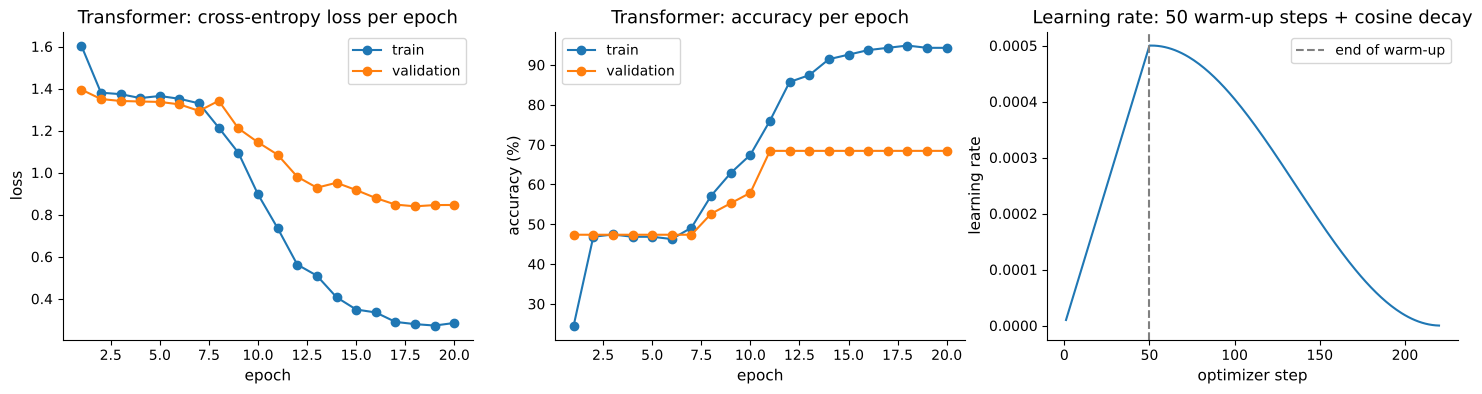

val accuracy per epoch: [47.4, 47.4, 47.4, 47.4, 47.4, 47.4, 47.4, 52.6, 55.3, 57.9, 68.4, 68.4, 68.4, 68.4, 68.4, 68.4, 68.4, 68.4, 68.4, 68.4]


In [37]:
h = res_tf["history"]; ep = range(1, len(h["train_loss"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].plot(ep, h["train_loss"], marker="o", label="train"); ax[0].plot(ep, h["val_loss"], marker="o", label="validation")
ax[0].set_title("Transformer: cross-entropy loss per epoch"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend()
ax[1].plot(ep, h["train_acc"], marker="o", label="train"); ax[1].plot(ep, h["val_acc"], marker="o", label="validation")
ax[1].set_title("Transformer: accuracy per epoch"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy (%)"); ax[1].legend()
ax[2].plot(range(1, len(h["lr"]) + 1), h["lr"]); ax[2].axvline(C.TF_WARMUP, color="grey", ls="--", label="end of warm-up")
ax[2].set_title("Learning rate: 50 warm-up steps + cosine decay"); ax[2].set_xlabel("optimizer step"); ax[2].set_ylabel("learning rate"); ax[2].legend()
savefig(fig, "transformer_training_curves.png"); plt.show()
print("val accuracy per epoch:", [round(x, 1) for x in h["val_acc"]])

## 8. Evaluation

### 8.1 Results (test set, best-validation checkpoint, seed 42)

Transformer test accuracy 78.38%, macro-F1 72.90  (37 test articles)
(model after the last epoch: accuracy 78.38%, macro-F1 72.90)


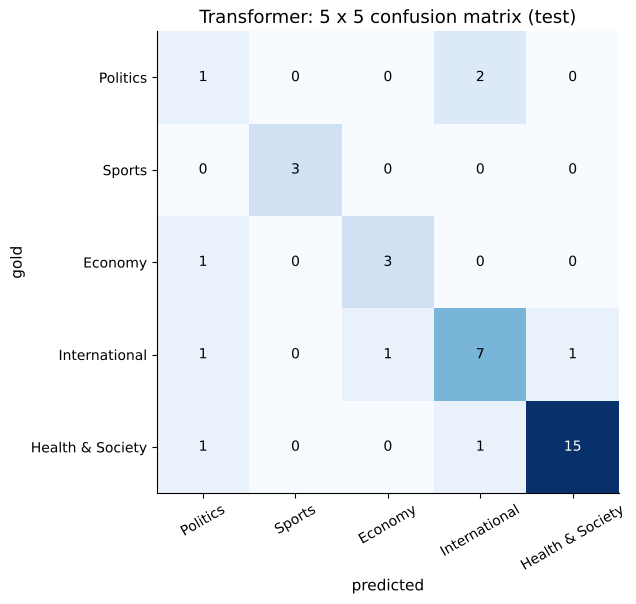

,precision,recall,f1,support
Politics,0.250,0.333,0.286,3.0
Sports,1.000,1.000,1.000,3.0
Economy,0.750,0.750,0.750,4.0
International,0.700,0.700,0.700,10.0
Health & Society,0.938,0.882,0.909,17.0


In [38]:
Xte, yte, Lte, test_idx = subset(data3, "test")
ev_tf = evaluate(res_tf["model"], Xte, yte, Lte)
final_model = make_transformer(w2i); final_model.load_state_dict(res_tf["final_state"])
ev_tf_final = evaluate(final_model, Xte, yte, Lte)
RESULTS["transformer_test"] = {"accuracy": ev_tf["accuracy"], "macro_f1": ev_tf["macro_f1"], "best_epoch": res_tf["best_epoch"],
                               "final_epoch_accuracy": ev_tf_final["accuracy"], "final_epoch_macro_f1": ev_tf_final["macro_f1"]}
print(f"Transformer test accuracy {ev_tf['accuracy']:.2f}%, macro-F1 {ev_tf['macro_f1']:.2f}  ({len(yte)} test articles)")
print(f"(model after the last epoch: accuracy {ev_tf_final['accuracy']:.2f}%, macro-F1 {ev_tf_final['macro_f1']:.2f})")
cm5 = ev_tf["confusion"]
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm5, cmap="Blues")
for i in range(5):
    for j in range(5): ax.text(j, i, cm5[i, j], ha="center", va="center", color="white" if cm5[i, j] > cm5.max() / 2 else "black")
ax.set_xticks(range(5)); ax.set_xticklabels(C.CATEGORIES, rotation=30); ax.set_yticks(range(5)); ax.set_yticklabels(C.CATEGORIES)
ax.set_xlabel("predicted"); ax.set_ylabel("gold"); ax.set_title("Transformer: 5 x 5 confusion matrix (test)")
savefig(fig, "transformer_confusion_matrix.png"); plt.show()
pd.DataFrame(per_class_prf(yte.tolist(), ev_tf["pred"], list(range(5))), ).T.set_axis(C.CATEGORIES).round(3)

**Attention heatmaps** — final encoder layer, all 4 heads, for 3 correctly classified test articles.
Each map shows the first 24 positions ([CLS] + 23 tokens; the full 257 × 257 map is unreadable); the bar
chart lists the 12 tokens the [CLS] position attends to most over the whole sequence (head average).

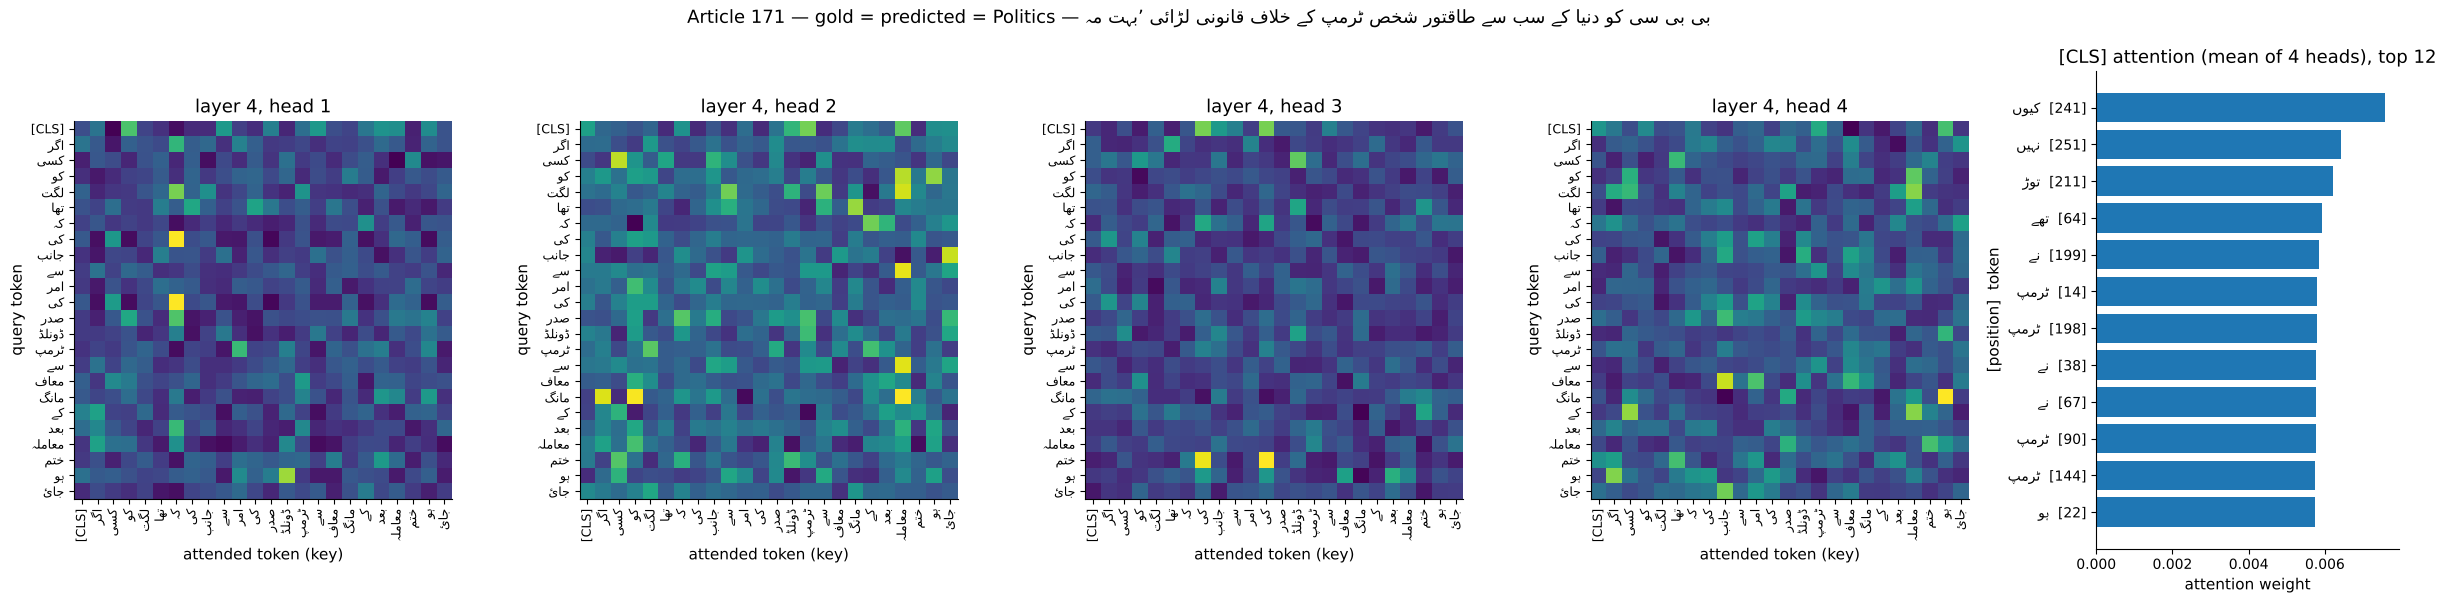

article 171 (Politics): top [CLS]-attended tokens: کیوں، نہیں، توڑ، تھے، نے، ٹرمپ، ٹرمپ، نے، نے، ٹرمپ، ٹرمپ، ہو


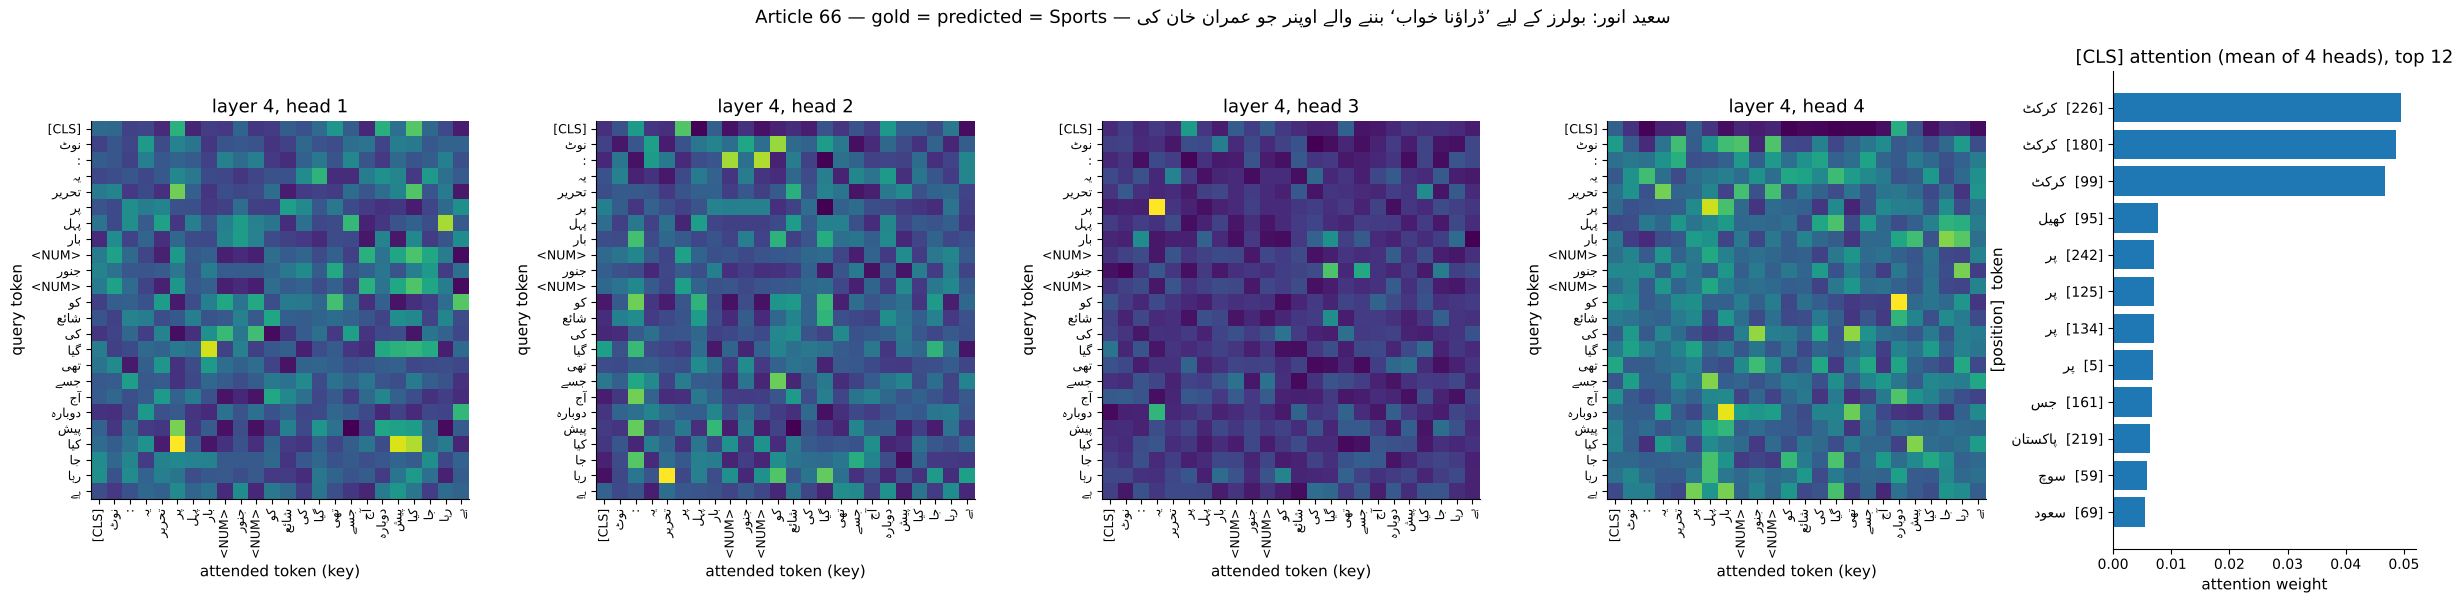

article 66 (Sports): top [CLS]-attended tokens: کرکٹ، کرکٹ، کرکٹ، کھیل، پر، پر، پر، پر، جس، پاکستان، سوچ، سعود


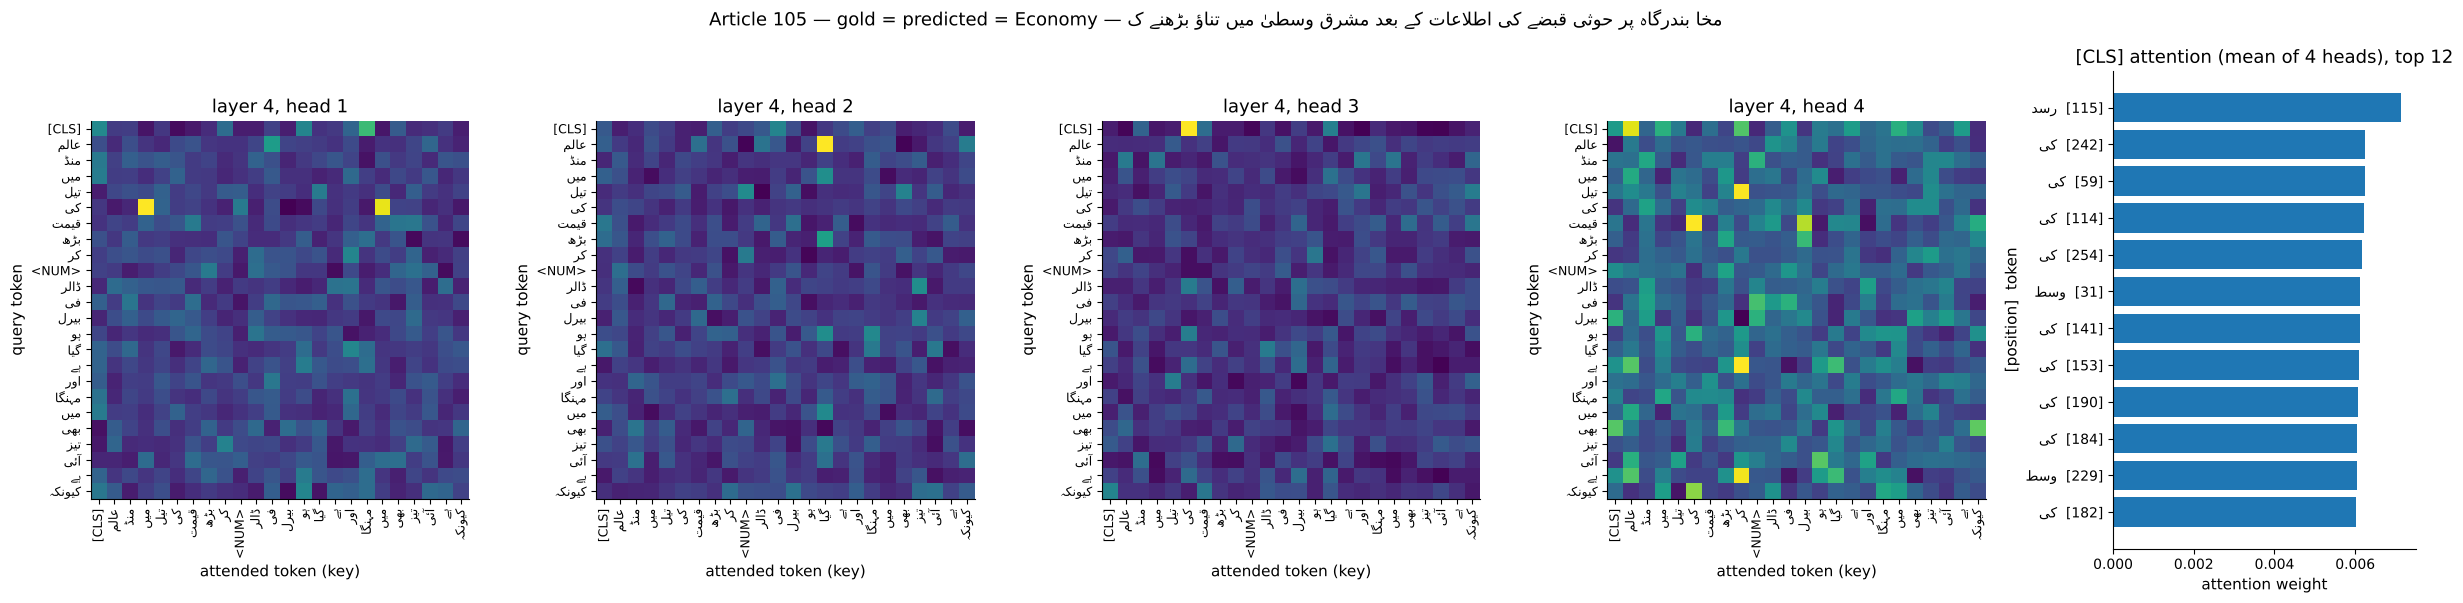

article 105 (Economy): top [CLS]-attended tokens: رسد، کی، کی، کی، کی، وسط، کی، کی، کی، کی، وسط، کی


In [39]:
model_tf = res_tf["model"].eval()
correct = [k for k in range(len(yte)) if ev_tf["pred"][k] == int(yte[k])]
chosen = []
for c in range(5):                    # prefer 3 different categories
    for k in correct:
        if int(yte[k]) == c and len(chosen) < 3: chosen.append(k); break
for k in correct:
    if len(chosen) < 3 and k not in chosen: chosen.append(k)
SHOW = 24
for k in chosen:
    art_no = int(test_idx[k]) + 1
    with torch.no_grad(): _, att = model_tf(Xte[k:k+1], return_attention=True)
    A = att[-1][0].numpy()                                   # (heads, T+1, T+1)
    toks = ["[CLS]"] + [i2w[int(t)] for t in Xte[k][:SHOW - 1]]
    fig, axes = plt.subplots(1, 5, figsize=(30, 6.2), gridspec_kw={"width_ratios": [1, 1, 1, 1, 0.8]})
    for hd in range(4):
        ax = axes[hd]; ax.imshow(A[hd, :SHOW, :SHOW], cmap="viridis")
        ax.set_xticks(range(SHOW)); ax.set_xticklabels(toks, rotation=90, fontsize=9)
        ax.set_yticks(range(SHOW)); ax.set_yticklabels(toks, fontsize=9)
        ax.set_title(f"layer 4, head {hd + 1}"); ax.set_xlabel("attended token (key)"); ax.set_ylabel("query token")
    n_real = int(Lte[k]); cls_att = A[:, 0, 1:n_real + 1].mean(0)
    top = np.argsort(-cls_att)[:12]
    axes[4].barh(range(len(top)), cls_att[top][::-1], color=PALETTE[0])
    axes[4].set_yticks(range(len(top))); axes[4].set_yticklabels([f"[{j+1}]  {i2w[int(Xte[k][j])]}" for j in top][::-1], fontsize=10)
    axes[4].set_title("[CLS] attention (mean of 4 heads), top 12"); axes[4].set_xlabel("attention weight"); axes[4].set_ylabel("[position]  token")
    fig.subplots_adjust(wspace=0.35)
    fig.suptitle(f"Article {art_no} — gold = predicted = {C.CATEGORIES[int(yte[k])]} — {meta[art_no-1]['title'][:70]}", fontsize=13)
    savefig(fig, f"attention_article_{art_no}.png"); plt.show()
    print(f"article {art_no} ({C.CATEGORIES[int(yte[k])]}): top [CLS]-attended tokens:",
          "، ".join(f"{i2w[int(Xte[k][j])]}" for j in top))

### 8.2 BiLSTM vs Transformer

For a like-for-like comparison a BiLSTM classifier is trained on the **same** split and inputs:
C3-initialised embeddings (fine-tuned) → 2-layer BiLSTM (128 per direction, dropout 0.5 between layers)
→ masked mean + max pooling → MLP (512 → 64 → 5); Adam (10⁻³, wd 10⁻⁴), 20 epochs, batch 16,
best-validation checkpoint. Both models are run with the 3 seeds; the seed-42 runs are shown in detail.

In [40]:
torch.manual_seed(C.SEED)
bl = BiLSTMClassifier(emb, pad_idx)
res_bl = train_classifier(bl, data3, "bilstm", RUN["tf_epochs"], C.SEQ_LR, C.SEQ_WEIGHT_DECAY, C.TF_BATCH, seed=C.SEED)
ev_bl = evaluate(res_bl["model"], Xte, yte, Lte)
print(f"BiLSTM test accuracy {ev_bl['accuracy']:.2f}%, macro-F1 {ev_bl['macro_f1']:.2f}; best val epoch {res_bl['best_epoch']}")

  [bilstm] epoch  1  train loss 1.5198 acc  42.3  |  val loss 1.3395 acc  47.4 macro-F1  12.9  (2.0s)


  [bilstm] epoch  2  train loss 1.3615 acc  46.9  |  val loss 1.3389 acc  47.4 macro-F1  12.9  (1.7s)


  [bilstm] epoch  3  train loss 1.3536 acc  46.9  |  val loss 1.2820 acc  47.4 macro-F1  12.9  (1.6s)


  [bilstm] epoch  4  train loss 1.2548 acc  46.9  |  val loss 1.2135 acc  47.4 macro-F1  12.9  (1.7s)


  [bilstm] epoch  5  train loss 1.2122 acc  48.6  |  val loss 1.9882 acc  47.4 macro-F1  12.9  (1.6s)


  [bilstm] epoch  6  train loss 1.2934 acc  56.0  |  val loss 1.1278 acc  63.2 macro-F1  27.2  (1.9s)


... (10 outputs left out)

  [bilstm] epoch 17  train loss 0.4793 acc  84.0  |  val loss 0.6279 acc  71.1 macro-F1  46.7  (1.7s)


  [bilstm] epoch 18  train loss 0.3413 acc  86.9  |  val loss 0.6804 acc  73.7 macro-F1  60.9  (1.6s)


  [bilstm] epoch 19  train loss 0.4331 acc  84.6  |  val loss 1.2240 acc  65.8 macro-F1  39.8  (1.5s)


  [bilstm] epoch 20  train loss 0.3622 acc  89.7  |  val loss 0.7705 acc  71.1 macro-F1  52.0  (1.6s)
BiLSTM test accuracy 67.57%, macro-F1 47.29; best val epoch 13


In [41]:
cmp_runs = {"Transformer": {42: (res_tf, ev_tf)}, "BiLSTM": {42: (res_bl, ev_bl)}}
for seed in RUN["seeds"][1:]:
    torch.manual_seed(seed); m = make_transformer(w2i)
    r = train_classifier(m, data3, "transformer", RUN["tf_epochs"], C.TF_LR, C.TF_WEIGHT_DECAY, C.TF_BATCH, seed=seed, verbose=False)
    cmp_runs["Transformer"][seed] = (r, evaluate(r["model"], Xte, yte, Lte))
    torch.manual_seed(seed); m = BiLSTMClassifier(emb, pad_idx)
    r = train_classifier(m, data3, "bilstm", RUN["tf_epochs"], C.SEQ_LR, C.SEQ_WEIGHT_DECAY, C.TF_BATCH, seed=seed, verbose=False)
    cmp_runs["BiLSTM"][seed] = (r, evaluate(r["model"], Xte, yte, Lte))
rows = []
for name, d in cmp_runs.items():
    accs = [ev["accuracy"] for _, ev in d.values()]; f1s = [ev["macro_f1"] for _, ev in d.values()]
    best_eps = [r["best_epoch"] for r, _ in d.values()]
    secs = [np.mean(r["history"]["epoch_seconds"]) for r, _ in d.values()]
    mdl = d[42][0]["model"]
    rows.append({"model": name, "parameters": sum(p.numel() for p in mdl.parameters()),
                 "test acc (seed 42)": round(d[42][1]["accuracy"], 2), "test macro-F1 (seed 42)": round(d[42][1]["macro_f1"], 2),
                 "test acc mean ± std": ms(accs), "test macro-F1 mean ± std": ms(f1s),
                 "best val epoch per seed": best_eps, "seconds / epoch (mean)": round(float(np.mean(secs)), 2)})
cmp_df = pd.DataFrame(rows); RESULTS["bilstm_vs_transformer"] = cmp_df.to_dict("records")
cmp_df

,model,parameters,test acc (seed 42),test macro-F1 (seed 42),test acc mean ± std,test macro-F1 mean ± std,best val epoch per seed,seconds / epoch (mean)
0,Transformer,2082309,78.38,72.90,77.48 ± 3.37,64.71 ± 7.23,"[18, 17, 17]",3.89
1,BiLSTM,1664141,67.57,47.29,71.17 ± 3.37,54.23 ± 5.24,"[13, 19, 15]",1.65


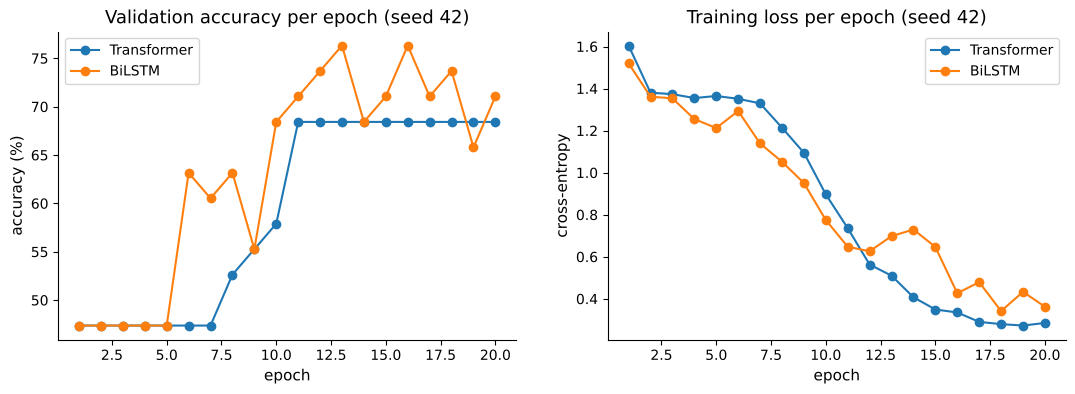

BiLSTM confusion matrix (seed 42):
                  Politics  Sports  Economy  International  Health & Society
Politics                 0       0        1              2                 0
Sports                   0       2        0              1                 0
Economy                  0       2        1              1                 0
International            0       0        2              8                 0
Health & Society         0       0        0              3                14


In [42]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, d in cmp_runs.items():
    hh = d[42][0]["history"]; ep = range(1, len(hh["val_acc"]) + 1)
    ax[0].plot(ep, hh["val_acc"], marker="o", label=name); ax[1].plot(ep, hh["train_loss"], marker="o", label=name)
ax[0].set_title("Validation accuracy per epoch (seed 42)"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("accuracy (%)"); ax[0].legend()
ax[1].set_title("Training loss per epoch (seed 42)"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("cross-entropy"); ax[1].legend()
savefig(fig, "bilstm_vs_transformer.png"); plt.show()
print("BiLSTM confusion matrix (seed 42):"); print(pd.DataFrame(ev_bl["confusion"], index=C.CATEGORIES, columns=C.CATEGORIES))

**BiLSTM vs Transformer — answers to the five questions (13 sentences).**

**1. Accuracy.** The Transformer achieves the higher test accuracy: 78.4% against 67.6% for the BiLSTM with seed 42, a gap of 10.8 points. Averaged over three seeds the gap is 6.3 points in accuracy (77.5 ± 3.4% vs 71.2 ± 3.4%) and 10.5 points in macro-F1 (64.7 vs 54.2), and the seed-42 BiLSTM never predicts the Politics class.

**2. Convergence.** The BiLSTM converged in fewer epochs: its best validation epoch was 13, 19 and 15 for the three seeds (mean 15.7), against 18, 17 and 17 for the Transformer (mean 17.3). With seed 42 the BiLSTM left the majority-class baseline of 47.4% at epoch 6, while the Transformer stayed there for the first 7 epochs of warm-up and early training and reached its validation plateau of 68.4% only at epoch 11.

**3. Speed.** The BiLSTM was also about 2.4 times faster per epoch (1.65 s against 3.89 s on the same CPU). Self-attention computes 257 × 257 scores in each of 4 heads and 4 layers and applies a 512-wide feed-forward network at every position, and our from-scratch layer processes the four separately projected heads one after another. The LSTM, in contrast, is a single optimised library kernel whose cost grows only linearly with the sequence length, and it has fewer parameters (1.66 M against 2.08 M).

**4. Attention.** The heatmaps show that the final-layer [CLS] token focuses on topic words: in the Sports article the three occurrences of کرکٹ (cricket) each receive about 0.05 attention, roughly seven times more than any other token. In the Politics article the [CLS] attention is much flatter, but four occurrences of ٹرمپ (Trump) are among its 12 most-attended tokens, and in the Economy article رسد (supply) ranks first. Frequent function words such as کی، پر and نے also collect attention as default positions, and the four heads differ in how sharply they focus.

**5. Which architecture for 200–300 articles?** For this task we would choose the Transformer, because topic labels depend mainly on which keywords occur, and the [CLS] attention pools such keywords from anywhere in the 256-token window, whereas the BiLSTM must carry them through 256 sequential steps. This recommendation is tentative: the Transformer needs warm-up and 8 epochs to leave the majority class, and its macro-F1 varies by ±7 points across seeds. Its 6-point advantage also corresponds to only 2–3 of the 37 test articles, and on the 38 validation articles the seed-42 BiLSTM even scored higher (76.3% against 68.4%), so the cheaper and faster-converging BiLSTM remains a reasonable alternative.

## Saved artefacts

The three saved models are re-loaded from disk and re-evaluated on the test sets to check that the files
reproduce the reported numbers.

In [43]:
from corpus import load_word2idx
w2i_disk = load_word2idx(); assert w2i_disk == w2i
checks = []
for task, fname in (("pos", "bilstm_pos.pt"), ("ner", "bilstm_ner.pt")):
    ck = torch.load(C.MODELS / fname, weights_only=False); cfg = SeqConfig(**ck["config"])
    m = BiLSTMTagger(len(ck["tags"]), len(w2i_disk), C.W2V_DIM, pad_idx=ck["pad_idx"], hidden=cfg.hidden,
                     layers=cfg.layers, dropout=cfg.dropout, bidirectional=cfg.bidirectional, use_crf=cfg.use_crf)
    m.load_state_dict(ck["state_dict"])
    _, _, f1 = run_eval(m, DATA2[task]["test"], cfg, ck["pad_idx"], ck["tags"])
    checks.append({"file": f"models/{fname}", "reported test F1": round(ck["test_f1"], 2), "re-loaded test F1": round(f1, 2)})
ck = torch.load(C.MODELS / "transformer_cls.pt", weights_only=False)
m = make_transformer(w2i_disk); m.load_state_dict(ck["state_dict"])
checks.append({"file": "models/transformer_cls.pt", "reported test F1": round(ev_tf["macro_f1"], 2),
               "re-loaded test F1": round(evaluate(m, Xte, yte, Lte)["macro_f1"], 2)})
pd.DataFrame(checks)

,file,reported test F1,re-loaded test F1
0,models/bilstm_pos.pt,87.81,87.81
1,models/bilstm_ner.pt,64.76,64.76
2,models/transformer_cls.pt,72.90,72.90


In [44]:
RESULTS["run"] = RUN
(C.OUT / "results.json").write_text(json.dumps(RESULTS, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
for p in sorted(list(C.EMB.glob("*")) + list(C.MODELS.glob("*")) + list(C.DATA.glob("*.conll"))):
    print(f"{str(p.relative_to(Path.cwd())):35s} {p.stat().st_size/1e6:9.2f} MB")
print("results -> outputs/results.json; figures ->", len(list(C.FIG.glob('*.png'))), "PNG files in figures/")

data/ner_test.conll                      0.02 MB
data/ner_train.conll                     0.09 MB
data/ner_val.conll                       0.02 MB
data/pos_test.conll                      0.02 MB
data/pos_train.conll                     0.12 MB
data/pos_val.conll                       0.02 MB
embeddings/embeddings_w2v.npy            4.00 MB
embeddings/ppmi_matrix.npy             400.08 MB
embeddings/ppmi_matrix_sparse.npz        3.77 MB
embeddings/tfidf_matrix.npy             10.00 MB
embeddings/word2idx.json                 0.19 MB
models/bilstm_ner.pt                     6.54 MB
models/bilstm_pos.pt                     6.54 MB
models/transformer_cls.pt                8.51 MB
results -> outputs/results.json; figures -> 14 PNG files in figures/
